#**Multiclass Flight Anomaly Detection Incorporating Arrival Airport and Runway Context**

## **PROJECT SUMMARY**

**PROJECT BACKGROUND AND OBJECTIVES**

Despite the historically high safety performance of commercial aviation, the continued reduction of aviation accidents and safety-related incidents requires **proactive identification of flight anomalies and their associated risk factors**. Machine learning (ML) techniques have increasingly been applied to aviation safety analysis to identify complex patterns in flight data, improve anomaly detection, and support data-driven safety risk assessment.
However, many existing studies have primarily employed **binary classification approaches**, distinguishing between nominal (Normal Operation) and anomalous flights without explicitly differentiating among anomaly types. Although some studies, such as **Memarzadeh et al. (2021)**, have explored multiclass anomaly classification, relatively limited attention has been devoted for identifying distinct types of flight anomalies.

Accordingly, this project pursued two primary objectives. The first was to **develop and compare multiple machine learning models for multiclass flight anomaly classification** in commercial aviation, distinguishing among **Nominal, Speed High, Path High, and Flaps Late** flight conditions. The second objective was to **identify and assess the key flight characteristics and operational factors associated with different types of flight anomalies**, providing insights that could support proactive aviation safety management and risk identification.



**FLIGHT DATA:**

This project used the **NASA DASHlink Multi-Class Anomaly Classification Dataset**, publicly available through NASA's DASHlink repository. The dataset contains time-series flight trajectory data collected during the approach-to-landing phase, with flights categorized into four classes: **Nominal, Speed High, Path High, and Flaps Late**. Each flight consists of **160 time-step observations**, with each time step containing measurements of multiple flight parameters, such as airspeed, altitude, and other aircraft operational characteristics.

Several statistical aggregation methods, including **mean and standard deviation, maximum, and median**, were evaluated to transform the time-step observations into flight-level features. Based on this comparison, **mean and standard deviation were selected** to represent the flight-level characteristics used in the classification models.
Exploratory data analysis revealed a **substantial class imbalance**, with three anomalous flights together accounting for approximately **10%** of the total observations, indicating that the target variable was **imbalanced**.


**MACHINE LEARNING MODEL DEVELOPMENT AND EVALUATION:**

Four supervised machine learning algorithms were built and compared to detect multicalss anomalous flights and contributing factors, including:  

- Balanced Random Forest (**BRF**)
- Extreme Gradient Boosting Classifier (**XGBoost**) *(with/without SMOTE resampling)*
- Light Gradient Boosting Machine (**LightGBM**) *(with/without SMOTE resampling)*
- Artificial Neural Networks (**NN**)  

The training set was used for model development and hyperparameter tuning, while the test set was reserved for final performance evaluation. Model performance was assessed using **Macro Precision, Macro Recall, Macro F1-score, and Macro Average Precision (AP)**. Given the substantial class imbalance, **macro-averaged metrics** were employed to assign equal importance to all four flight classes, regardless of their relative frequencies. Particular emphasis was placed on **Macro F1-score as the primary model-selection criterion**, as it balances precision and recall across classes and provides a more representative assessment of multiclass classification performance than overall accuracy. Additionally, **class-specific precision and recall** were examined to evaluate each model's ability to identify minority anomaly classes.


**MODELING RESULTS AND DISCUSSION:**

The comparative analysis showed that **XGBoost yielded the highest overall classification performance**, with a **Macro F1-score of 0.811**, closely followed by the **LightGBM** and **NN**, both with a Macro F1-score of **0.808**. **BRF** had lower Macro F1-scores of **0.570**, while it achieved the highest **Macro Recall (0.850)**, indicating greater sensitivity across the four flight classes.

**XGBoost** was subsequently selected for **SHAP (SHapley Additive exPlanations) analysis** to evaluate the relative importance of the selected predictors and examine their contributions to model predictions across the four flight classes. Both global and class-specific SHAP analyses were conducted to assess the magnitude and direction of each feature's influence on the model output.

The **SHAP analysis** identified `airspeed_mean` as the most influential predictor, followed by `airspeed_std`, `tot_pressure_std`, and `altitude_std`. However, the effect of each predictor on class probability varied by class. For example, the **class-specific SHAP analysis** revealed higher mean airspeed (`airspeed_mean`) generally contributed positively to **Speed High** and **Flaps Late** predictions but negatively to **Nominal** predictions. Greater altitude variability (`altitude_std`), pitch-angle variability (`pitch_angle_std`), and flight-path deviations (`loc_dev_std` and `gl_slp_dev_mean`) were particularly influential in identifying **Path High** anomalies. For **Flaps Late**, higher mean airspeed and mean pitch angle (`pitch_angle_mean`) generally increased the class prediction scores, whereas higher airspeed variability (`airspeed_std`) contributed negatively.

---

**PROJECT CONTRIBUTIONS/MERIT:**

The primary contribution of this project is the incorporation of **arrival airport and runway information as contextual predictors** in a multiclass flight anomaly classification framework. Unlike previous similar projects that have primarily relied on flight-specific parameters, this study has integrated operational context to distinguish among four flight categories: **Nominal, Speed High, Path High, and Flaps Late**. The inclusion of these contextual features also improved predictive performance by approximately **??%**, highlighting their potential value for anomaly detection. **A similar improvement was observed in my earlier binary classification project**, where incorporating arrival airport and runway information enhanced the predictive performance of the classification models.

Another key contribution of this project is the development of a **multiclass flight anomaly classification framework**, extending beyond the binary classification approaches commonly employed in previous studies, where different anomaly types have often been grouped into a single category. Rather than grouping the target variable into nominal and anomalous flights, this study enables the identification of **three distinct anomaly types: Speed High, Path High, and Flaps Late**, alongside the Nominal class. Furthermore, the project provides a **systematic comparative evaluation of four machine learning algorithms and class imbalance-handling strategies** within a multiclass classification framework.

Collectively, these contributions support the development of a more **interpretable, context-aware multiclass flight anomaly classification framework**, capable of distinguishing among different anomalous flight behaviors rather than treating all anomalies as a single category.


---
---
---
---

## **Dataset Description**

### **Target Variable Distribution and Binary Classification**

| Class Index | Original Class | Count | Binary Outcome |
|:-----------:|--------------------|------:|----------------|
| 0 | Nominal | 89,663 | Normal Class |
| 1 | Speed High | 7,013 | Anomaly Class |
| 2 | Path High | 2,207 | Anomaly Class |
| 3 | Flaps Late Setting | 954 | Anomaly Class |
| **Total** | | **99,837** | |

---
---


### **Flight Features Used for Anomaly Detection**
It should be noted that the flap position (`flap_pos`) variable and its derived features (mean and standard deviation) were excluded to prevent potential target leakage, as flap position is directly associated with the definition of the **late-flap anomaly**. An initial analysis showed that **`flap_pos_mean` had the strongest influence on the binary anomaly response**, likely due to its direct relationship with late-flap settings. Therefore, **`flap_pos` and its derived features were excluded from the final model development.**


| Variable | Description |
|:---------|:------------|
| flight_id | Unique identifier for each flight |
| aileron_lh_mean | Mean left aileron position (degrees) |
| aileron_lh_std | Standard deviation of left aileron position (degrees) |
| aileron_rh_mean | Mean right aileron position (degrees) |
| aileron_rh_std | Standard deviation of right aileron position (degrees) |
| aoa_mean | Mean corrected angle of attack (degrees) |
| aoa_std | Standard deviation of corrected angle of attack (degrees) |
| altitude_mean | Mean barometric corrected altitude (feet) |
| altitude_std | Standard deviation of barometric corrected altitude (feet) |
| airspeed_mean | Mean computed airspeed relative to the surrounding air (knots) |
| airspeed_std | Standard deviation of computed airspeed (knots) |
| sel_course_mean | Mean selected course for the aircraft/autopilot (degrees) |
| sel_course_std | Standard deviation of selected course (degrees) |
| drift_angle_mean | Mean angle between aircraft heading and aircraft track (degrees) |
| drift_angle_std | Standard deviation of the drift angle (degrees) |
| elevator_l_mean | Mean left elevator position used to control aircraft pitch (degrees) |
| elevator_l_std | Standard deviation of left elevator position (degrees) |
| gl_slp_dev_mean | Mean deviation from the desired glide slope during approach (%) |
| gl_slp_dev_std | Standard deviation of glide-slope deviation (%) |
| sel_heading_mean | Mean selected heading for the aircraft/autopilot (degrees) |
| sel_heading_std | Standard deviation of selected heading (degrees) |
| loc_dev_mean | Mean localizer deviation from the runway centerline during approach (%) |
| loc_dev_std | Standard deviation of localizer deviation (%) |
| core_speed_mean | Mean engine core speed, indicating engine/throttle operating level (%) |
| core_speed_std | Standard deviation of engine core speed (%) |
| tot_pressure_mean | Mean total pressure (millibar) |
| tot_pressure_std | Standard deviation of total pressure (millibar) |
| pitch_angle_mean | Mean angle between the aircraft longitudinal axis and the horizon (degrees) |
| pitch_angle_std | Standard deviation of aircraft pitch angle (degrees) |
| roll_angle_mean | Mean aircraft roll angle (degrees) |
| roll_angle_std | Standard deviation of aircraft roll angle (degrees) |
| rudder_pos_mean | Mean rudder position (degrees) |
| rudder_pos_std | Standard deviation of rudder position (degrees) |
| true_heading_mean | Mean aircraft true heading measured clockwise from true north (degrees) |
| true_heading_std | Standard deviation of true heading (degrees) |
| vert_accel_mean | Mean aircraft vertical acceleration (G) |
| vert_accel_std | Standard deviation of vertical acceleration (G) |
| wind_speed_mean | Mean wind speed (knots) |
| wind_speed_std | Standard deviation of wind speed (knots) |
| arrival_airport | Arrival airport associated with the flight |
| arrival_runway | Runway used or assigned for the aircraft's arrival |  



# **FLOWCHART OF THE MULTICLASS FLIGHT ANOMALY CLASSIFICATION FRAMEWORK**

---



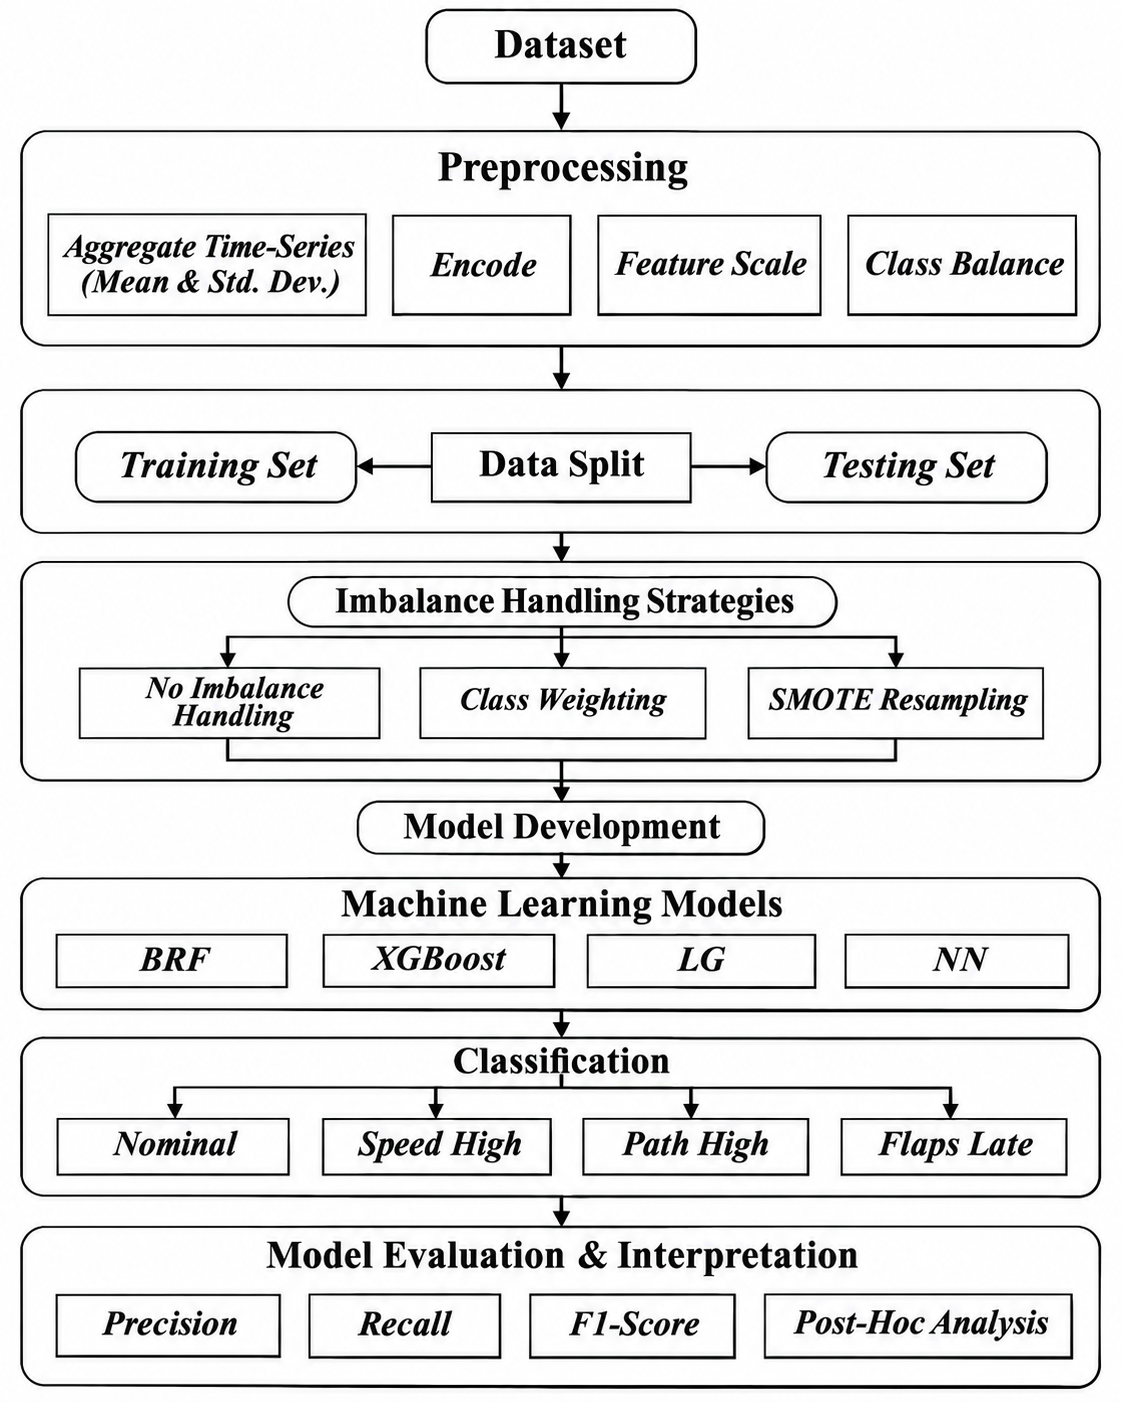

In [27]:
from IPython.display import Image, display
display(Image("/content/Machine Learning Flowchart.png", width=700))


# **STEP 1. Data Ingestion & Preprocessing**

The DASHlink dataset was retreived from NASA's DASHlink repository and restructured into a 2D panel format suitable for analysis.

In [1]:
# Load required libraries
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_recall_curve,
    PrecisionRecallDisplay)

from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, IsolationForest
import xgboost as xgb
import lightgbm as lgb
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler, TargetEncoder, label_binarize
from imblearn.over_sampling import SMOTE
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

pd.set_option('display.width', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)

# Load flight data and flight metadata
#df = np.load("DASHlink_full_fourclass_raw_comp.npz")
meta_df= pd.read_csv("DASHlink_full_fourclass_raw_meta.csv")


In [ ]:
var_df = df["data"]
label_df = df["label"]

print("Flight Feature Shape:")
print(var_df.shape, "\n") # var_df[flight, time_step, variable] >> Output: (99837, 160, 20)

print("Flight Label Shape:")
print(label_df.shape) # Output: (99837,)

In [ ]:
print("First Flight Data:")
print(var_df[:1, :, :], '\n\n') # var_df[0:1, :, :].shape # (1, 160, 20)
print("Last Flight Data:")
print(var_df[-1:, :, :]) # var_df[-1:, :, :].shape # (1, 160, 20)


array([[[81.26119   , 82.652336  , -8.111792  , ..., -1.0818703 ,
          0.9723786 , 12.625183  ],
        [79.604095  , 81.0157    , -7.6446114 , ..., -0.70481956,
          0.7700771 , 11.893839  ],
        [81.30211   , 80.7702    , -7.552573  , ..., -0.24044622,
          0.54393727, 12.559112  ],
        ...,
        [78.84715   , 81.93631   ,  0.14975742, ...,  0.68785334,
          1.0827516 ,  9.047807  ],
        [83.900276  , 84.698135  ,  1.3170995 , ...,  0.51355934,
          1.0503458 ,  8.270673  ],
        [82.5705    , 77.12868   ,  0.6525055 , ...,  0.29619697,
          1.0963339 ,  9.127736  ]]])

In [ ]:
print("First Flight: First 3 Time Steps × All 20 Features")
var_df[0,0:3,:] # First flight: all 20 variables for the first 3 time steps


array([[ 8.1261190e+01,  8.2652336e+01, -8.1117920e+00,  1.9696174e+03,
         1.5557140e+02, -2.1093580e+00, -6.9277790e-01, -4.9528540e+00,
         3.0650000e+03,  1.7940000e-02, -2.1093580e+00,  6.6640000e-03,
         7.0741180e+01,  9.8542550e+02, -3.6622615e+00,  7.8591200e-01,
        -3.9014083e-01, -1.0818703e+00,  9.7237860e-01,  1.2625183e+01],
       [ 7.9604095e+01,  8.1015700e+01, -7.6446114e+00,  1.9556995e+03,
         1.5451205e+02, -2.1093580e+00, -8.6721630e-01, -5.1983490e+00,
         3.0650000e+03,  1.9500000e-02, -2.1093580e+00,  7.4480000e-03,
         7.0717750e+01,  9.8552030e+02, -3.6652758e+00,  4.6774462e-02,
        -7.5623393e-01, -7.0481956e-01,  7.7007710e-01,  1.1893839e+01],
       [ 8.1302110e+01,  8.0770200e+01, -7.5525730e+00,  1.9400267e+03,
         1.5332867e+02, -2.1093580e+00, -1.4240930e+00, -4.8301050e+00,
         3.0650000e+03,  1.8720001e-02, -2.1093580e+00,  9.6040000e-03,
         7.0702760e+01,  9.8541650e+02, -3.9403190e+00,  8.048

## **Convert from 3D to 2D: (99837, 160, 20) --> [(99837*160, 20)=(15,973,920, 20)]**

**Original shape:** (99,837, 160, 20)

**Reshaped shape:** (15,973,920, 20)


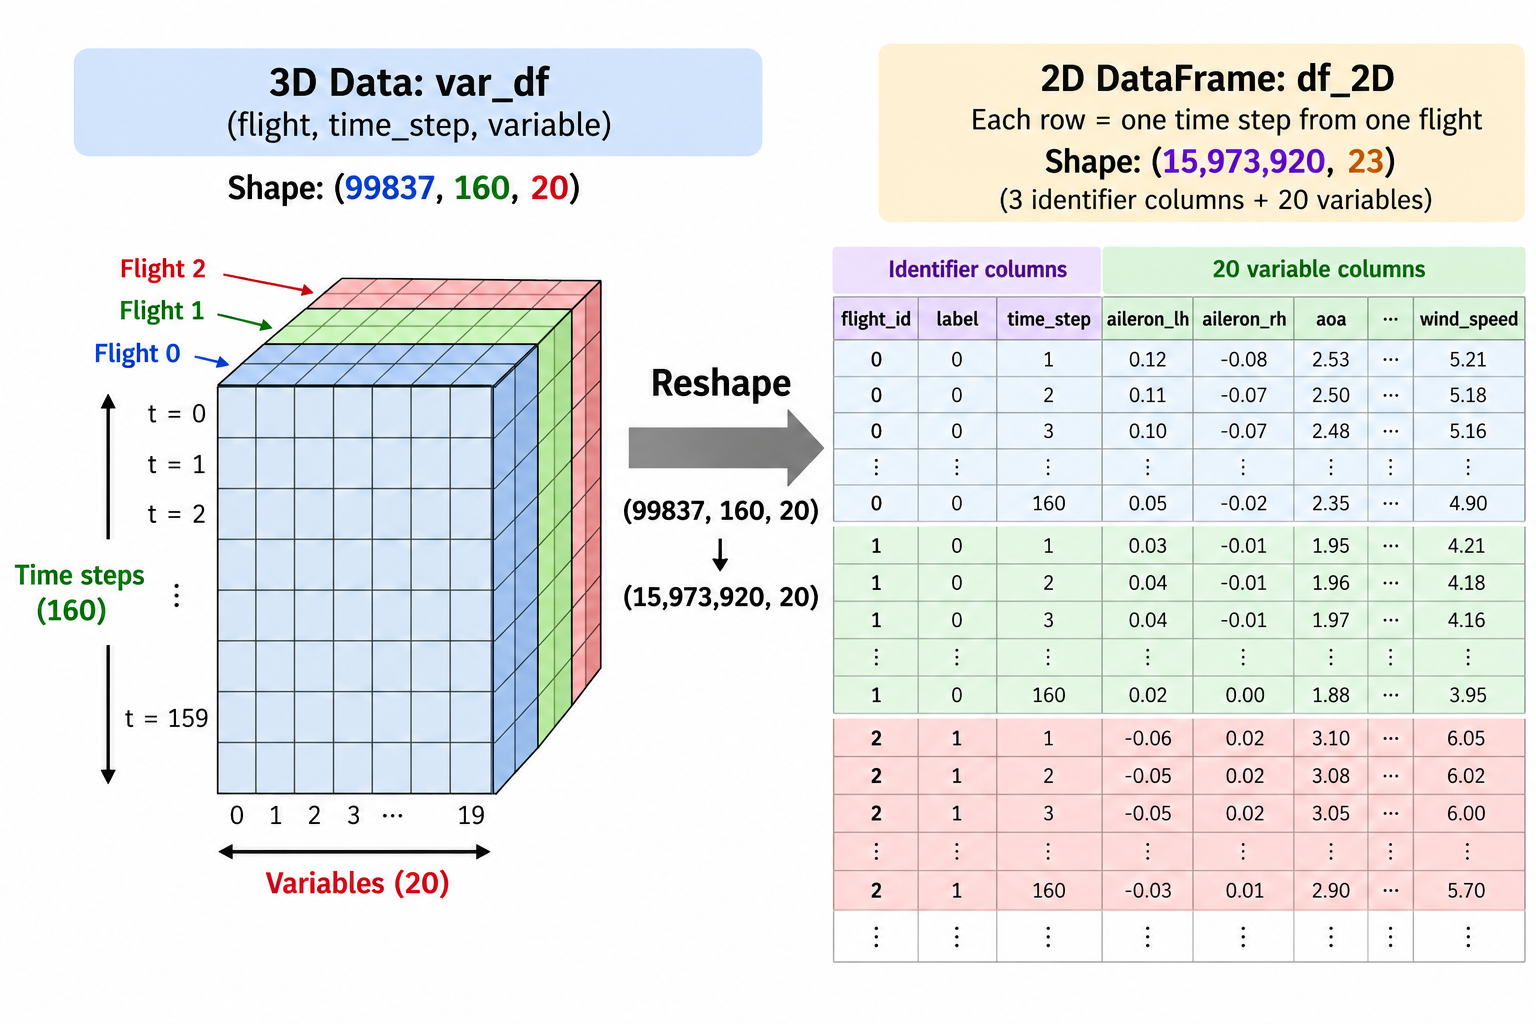

In [ ]:
from IPython.display import Image, display
display(Image("/content/3D-to-2D Data Conversion.png", width=700))


In [ ]:
# Original shape:
n_flights, n_timesteps, n_variables = var_df.shape # (99837, 160, 20)

# Convert var_df from 3D to 2D where each row represents one time step from one flight
var_df_2D=var_df.reshape(-1, n_variables) # 3D(99837, 160, 20) --> [(99837*160, 20)=(15,973,920, 20)]

# Create the DataFrame df_all for the var_df_2D:
# List of variables:
variable_names = ["aileron_lh", "aileron_rh", "aoa", "altitude", "airspeed", "sel_course", "drift_angle", "elevator_l", "flap_pos", "gl_slp_dev", "sel_heading",
    "loc_dev", "core_speed", "tot_pressure", "pitch_angle", "roll_angle", "rudder_pos", "true_heading", "vert_accel", "wind_speed"]

df_2D = pd.DataFrame(var_df_2D, columns=variable_names)

# Add flight_id to df_2D:
df_2D.insert(0, "flight_id", np.repeat(np.arange(n_flights), n_timesteps))

# Add label to df_2D
df_2D.insert(1, "label", np.repeat(label_df, n_timesteps))

# Add time_step to df_2D
df_2D.insert(2, "time_step", np.tile(np.arange(1, n_timesteps + 1), n_flights))

# Show the first 163 rows of df_2D
df_2D.head(163)


In [ ]:
# The dataset was examined for missing values. No missing values were observed in the dataset.
print("=" * 50)
print(f"Total observations:      {len(df_2D):,}")
print(f"Total missing values:    {df_2D.isnull().sum().sum():,}")
print(f"Variables with any NaN:  {(df_2D.isnull().sum() > 0).sum()}")
print("=" * 50)
print("Missing values per variable:")
print(df_2D.isnull().sum())


Total observations:      15,973,920
Total missing values:    0
Variables with any NaN:  0
Missing values per variable:
flight_id       0
label           0
time_step       0
aileron_lh      0
aileron_rh      0
aoa             0
altitude        0
airspeed        0
sel_course      0
drift_angle     0
elevator_l      0
flap_pos        0
gl_slp_dev      0
sel_heading     0
loc_dev         0
core_speed      0
tot_pressure    0
pitch_angle     0
roll_angle      0
rudder_pos      0
true_heading    0
vert_accel      0
wind_speed      0
dtype: int64


# **STEP 2. DATA PREPROCESSING AND FEATURE ENGINEERING**

### **Exploratory Data Analysis (EDA): Feature Distributions by Anomaly Status**


In [ ]:
model_features = df_2D.columns[~df_2D.columns.isin(['flight_id', 'label', 'time_step'])]

# Sample data for faster plotting
plot_df = df_2D.sample(300000, random_state=10)

fig, axes = plt.subplots(4, 5, figsize=(24, 16))
axes = axes.flatten()

for i, feature in enumerate(model_features):

    sns.boxplot(data=plot_df, x="label", y=feature, hue="label", palette="Set1", legend=False,ax=axes[i])

    axes[i].set_title(feature, fontweight="bold", fontsize=14)
    axes[i].set_xlabel("Label", fontweight="bold", fontsize=14)
    axes[i].set_ylabel(feature, fontweight="bold", fontsize=14)
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Normal", "Anomaly"])

for j in range(len(model_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


NameError: name 'df_2D' is not defined

### **Evaluation of Feature Aggregation Methods**

To transform the time-series flight data into flight-level features, three aggregation methods were initially evaluated: **mean, standard deviation, median, and maximum**. The temporal patterns of these statistics were compared between normal and anomalous flights for the selected flight variables. Based on this exploratory analysis, **mean and standard deviation** were retained for feature aggregation, as they provided useful information about both the **overall level** and **variability** of each flight characteristic.

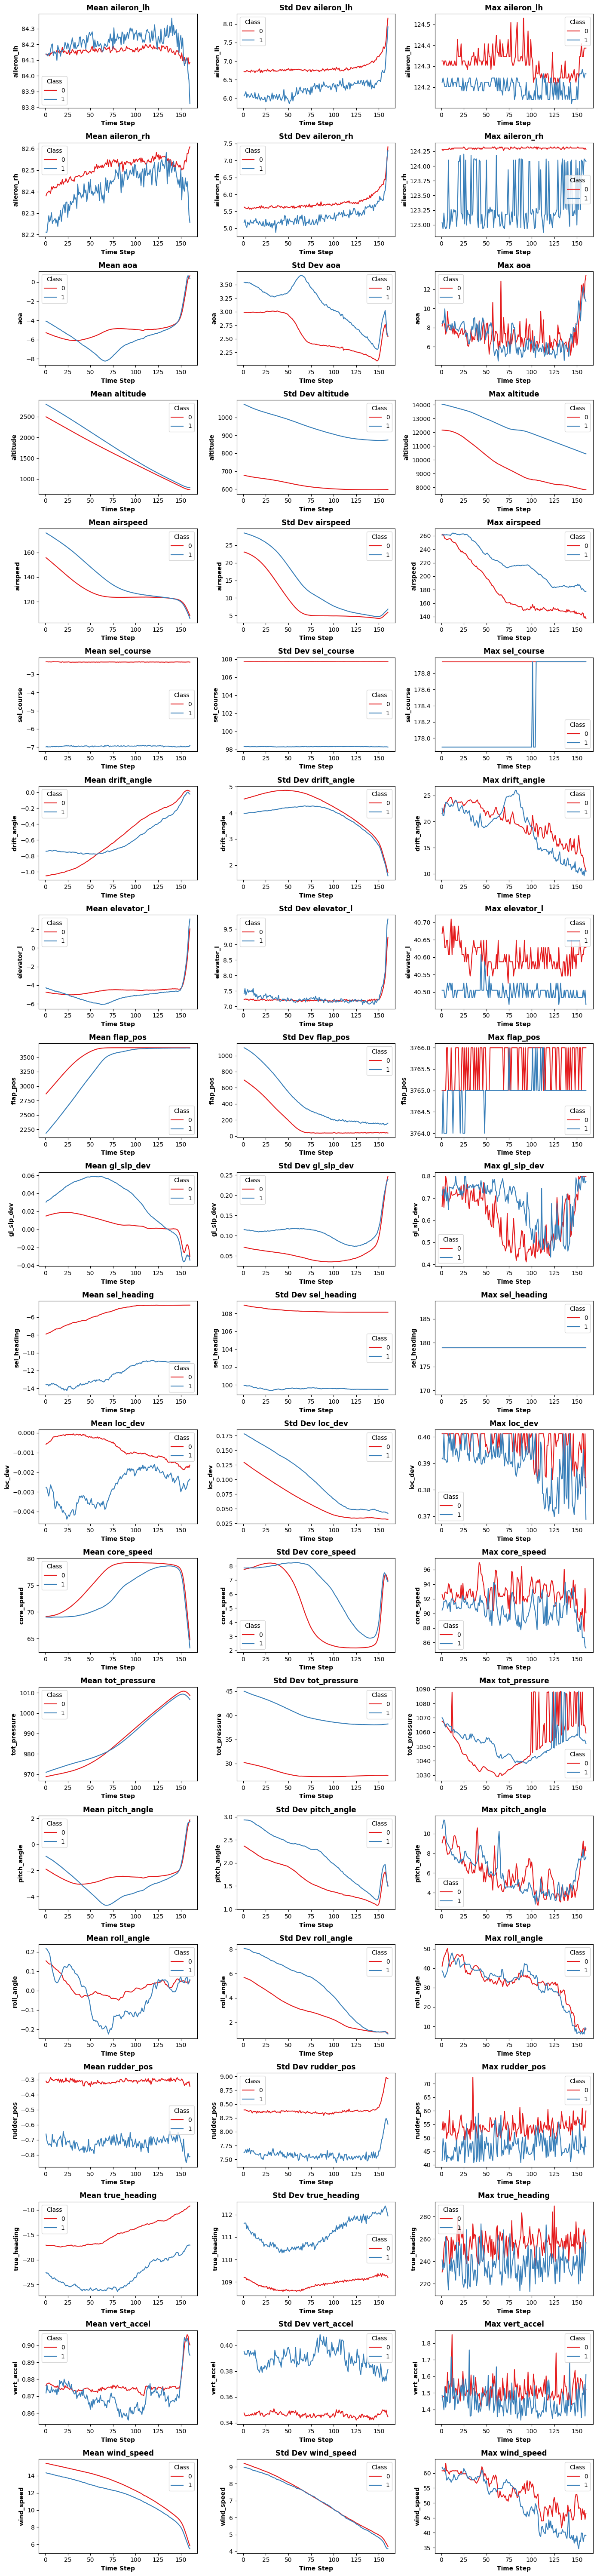

In [ ]:
fig, axes = plt.subplots(nrows=len(model_features), ncols=3, figsize=(14, 3*len(model_features)))
for i, feature in enumerate(model_features):
    # For Mean
    mean_feature = (df_2D.groupby(["time_step", "label"])[feature].mean().reset_index())
    sns.lineplot(data=mean_feature, x="time_step", y=feature, hue="label", palette="Set1", ax=axes[i, 0])
    axes[i, 0].set_title(f"Mean {feature}", fontweight="bold")
    axes[i, 0].set_xlabel("Time Step", fontweight="bold")
    axes[i, 0].set_ylabel(feature, fontweight="bold")
    axes[i, 0].legend(title="Class")

    # For Standard Deviation
    std_feature = (df_2D.groupby(["time_step", "label"])[feature].std().reset_index())
    sns.lineplot(data=std_feature, x="time_step", y=feature, hue="label", palette="Set1", ax=axes[i, 1])
    axes[i, 1].set_title(f"Std Dev {feature}", fontweight="bold")
    axes[i, 1].set_xlabel("Time Step", fontweight="bold")
    axes[i, 1].set_ylabel(feature, fontweight="bold")
    axes[i, 1].legend(title="Class")

    # For Max
    max_feature = ( df_2D.groupby(["time_step", "label"])[feature].max().reset_index())
    sns.lineplot(data=max_feature, x="time_step", y=feature, hue="label", palette="Set1", ax=axes[i, 2])
    axes[i, 2].set_title( f"Max {feature}", fontweight="bold")
    axes[i, 2].set_xlabel("Time Step", fontweight="bold")
    axes[i, 2].set_ylabel(feature, fontweight="bold")
    axes[i, 2].legend(title="Class")

plt.tight_layout()
plt.show()


In [ ]:
# Aggregate mean and standard deviation at flight level
df_agg_multiclass = (df_2D.groupby("flight_id")[model_features].agg(["mean", "std"]))

# Add mean and std suffixes to column names
df_agg_multiclass.columns = [f"{feature}_{stat}" for feature, stat in df_agg_multiclass.columns]

df_agg_multiclass = df_agg_multiclass.reset_index()

# Add flight-level target
target = (df_2D.groupby("flight_id")["label"].first().reset_index())

df_agg_multiclass = df_agg_multiclass.merge(target, on="flight_id", how="left")

df_agg_multiclass.head()


,flight_id,aileron_lh_mean,aileron_lh_std,aileron_rh_mean,aileron_rh_std,aoa_mean,aoa_std,altitude_mean,altitude_std,airspeed_mean,...,roll_angle_std,rudder_pos_mean,rudder_pos_std,true_heading_mean,true_heading_std,vert_accel_mean,vert_accel_std,wind_speed_mean,wind_speed_std,label
0,0,81.266564,1.818805,82.105597,4.912936,-4.565383,2.777340,1102.662484,457.001218,124.692591,...,1.204784,-0.706464,0.818808,0.381983,0.896360,0.929766,0.257088,10.789045,2.138787,0
1,1,81.213884,2.253339,82.342654,2.481823,-3.894063,2.952474,1993.313829,665.962731,140.545762,...,7.710989,-0.989186,1.616086,14.015765,9.604990,0.835092,0.399606,8.938388,2.296485,0
2,2,81.511548,2.052128,82.904738,1.999665,-3.104998,2.701813,1154.263600,531.137231,128.224637,...,2.192154,-1.409505,3.560667,-3.545832,4.669515,0.898057,0.348977,7.470958,1.715582,0
3,3,81.227437,1.571479,82.597101,1.812453,-3.726846,2.473116,901.706714,467.629577,123.039487,...,1.248944,-1.583777,3.590585,168.939981,1.234758,0.826536,0.406469,9.038239,1.837372,0
4,4,80.414104,6.249064,82.736598,0.962376,-5.567469,2.418550,1133.942162,479.356100,125.001667,...,0.637306,-0.280463,0.659386,2.333000,0.841506,0.891961,0.329723,9.872985,2.953472,0


# **df_agg_multiclass data entry**

In [2]:
df_agg_multiclass=pd.read_excel('df_agg_multi_class.xlsx')
df_agg_multiclass.drop(columns=["flap_pos_mean", "flap_pos_std"], axis=1, inplace=True)

# Convert numerical labels to flight anomaly names
class_names = {0: "Nominal", 1: "Speed High", 2: "Path High", 3: "Flaps Late"}
df_agg_multiclass["Flight Anomaly"] = df_agg_multiclass["label"].map(class_names)

df_agg_multiclass.head()


,flight_id,aileron_lh_mean,aileron_lh_std,aileron_rh_mean,aileron_rh_std,aoa_mean,aoa_std,altitude_mean,altitude_std,airspeed_mean,airspeed_std,sel_course_mean,sel_course_std,drift_angle_mean,drift_angle_std,elevator_l_mean,elevator_l_std,gl_slp_dev_mean,gl_slp_dev_std,sel_heading_mean,sel_heading_std,loc_dev_mean,loc_dev_std,core_speed_mean,core_speed_std,tot_pressure_mean,tot_pressure_std,pitch_angle_mean,pitch_angle_std,roll_angle_mean,roll_angle_std,rudder_pos_mean,rudder_pos_std,true_heading_mean,true_heading_std,vert_accel_mean,vert_accel_std,wind_speed_mean,wind_speed_std,label,Flight Anomaly
0,0,81.266564,1.818805,82.105597,4.912936,-4.565383,2.777340,1102.662484,457.001218,124.692591,9.214812,-2.109358,0.0,-1.209114,0.714210,-3.248447,1.009057,0.001394,0.025232,-2.109358,0.000000,0.002276,0.004258,77.591430,6.353414,1001.762683,13.432021,-1.895558,1.783895,-0.168108,1.204784,-0.706464,0.818808,0.381983,0.896360,0.929766,0.257088,10.789045,2.138787,0,Nominal
1,1,81.213884,2.253339,82.342654,2.481823,-3.894063,2.952474,1993.313829,665.962731,140.545762,22.163948,7.997990,0.0,-3.521659,1.228081,-5.063455,4.309041,0.080757,0.089431,4.688383,8.777953,0.009061,0.034343,70.653174,8.343218,981.482559,13.640569,-2.310019,1.736269,2.472004,7.710989,-0.989186,1.616086,14.015765,9.604990,0.835092,0.399606,8.938388,2.296485,0,Nominal
2,2,81.511548,2.052128,82.904738,1.999665,-3.104998,2.701813,1154.263600,531.137231,128.224637,10.725240,-2.109358,0.0,-0.150016,1.411378,-3.684458,1.558324,0.028307,0.051500,-8.903255,11.963090,-0.033397,0.055631,76.165936,8.885065,999.540228,15.304838,-1.778242,1.716118,0.608531,2.192154,-1.409505,3.560667,-3.545832,4.669515,0.898057,0.348977,7.470958,1.715582,0,Nominal
3,3,81.227437,1.571479,82.597101,1.812453,-3.726846,2.473116,901.706714,467.629577,123.039487,11.448093,165.936330,0.0,-2.409421,0.779628,-0.691325,1.284315,-0.000419,0.013665,165.936330,0.000000,0.004117,0.007157,76.475464,6.500893,1005.061422,13.080918,-1.604656,1.472162,-0.064167,1.248944,-1.583777,3.590585,168.939981,1.234758,0.826536,0.406469,9.038239,1.837372,0,Nominal
4,4,80.414104,6.249064,82.736598,0.962376,-5.567469,2.418550,1133.942162,479.356100,125.001667,5.171281,-2.109358,0.0,-3.222694,0.800244,-3.676786,3.207752,0.006196,0.031479,-2.109358,0.000000,-0.000940,0.002464,78.692939,5.729938,1000.680496,16.218605,-2.569867,1.416413,-0.468801,0.637306,-0.280463,0.659386,2.333000,0.841506,0.891961,0.329723,9.872985,2.953472,0,Nominal


### **Integrating Airport and Runway Information into Flight Features**


In [3]:
# Combine 'arrival_airport' and 'arrival_runway' into a single categorical feature ('arr_arprt_runway') ↲
# to capture airport-specific runway information before merging it with 'df_agg'.
meta_df['arr_arprt_runway']=meta_df["arrival_airport"] + "-" + meta_df["arrival_runway"]
print(meta_df['arrival_airport'].value_counts(), '\n')
print(meta_df['arr_arprt_runway'].value_counts())


arrival_airport
KMSP    25396
KDTW    18797
KMEM     9557
KOKC     2544
KDSM     2367
        ...  
KIDA        1
KLAN        1
KPVU        1
KCPS        1
KCWA        1
Name: count, Length: 97, dtype: int64 

arr_arprt_runway
KMSP-30R    7784
KMSP-12L    7313
KDTW-22R    6223
KDTW-21L    5821
KMSP-30L    5294
            ... 
KSTL-30R       1
KDEN-17R       1
KCPS-30L       1
KGRB-NAN       1
KBTV-19        1
Name: count, Length: 434, dtype: int64


In [4]:
# Group arrival airports and airport–runway combinations with fewer than ↲
# 10 observations into an "OTHER" category to reduce categorical sparsity.
counts_arr_arpt = meta_df["arrival_airport"].value_counts()
rare_arr_aprt_cat = counts_arr_arpt[counts_arr_arpt.values < 10].index
meta_df["arr_arprt"] = (meta_df["arrival_airport"].where(~meta_df["arrival_airport"].isin(rare_arr_aprt_cat), "OTHER"))
print(meta_df["arr_arprt"].value_counts(), '\n')

counts_arpt_runway = meta_df["arr_arprt_runway"].value_counts()
rare_arr_arpt_runway_cat= counts_arpt_runway[counts_arpt_runway.values < 10].index
meta_df["arr_arprt_rnwy"] = (meta_df["arr_arprt_runway"].where(~meta_df["arr_arprt_runway"].isin(rare_arr_arpt_runway_cat), "OTHER"))
print(meta_df["arr_arprt_rnwy"].value_counts(), '\n')


arr_arprt
KMSP     25396
KDTW     18797
KMEM      9557
KOKC      2544
KDSM      2367
         ...  
KGJT        40
OTHER       35
KHUL        32
KSBN        17
KCTB        12
Name: count, Length: 83, dtype: int64 

arr_arprt_rnwy
KMSP-30R    7784
KMSP-12L    7313
KDTW-22R    6223
KDTW-21L    5821
KMSP-30L    5294
            ... 
KMKE-1L       10
KPHL-9L       10
KATL-9R       10
KJAX-14       10
KICT-1R       10
Name: count, Length: 285, dtype: int64 



In [5]:
# Merge Arrival Airport-Runway filed into the "df_agg_multiclass" data:
df_agg_multiclass = df_agg_multiclass.merge(meta_df[["data_instance", "arr_arprt", "arr_arprt_rnwy"]], left_on="flight_id", right_on="data_instance", how="left")
df_agg_multiclass.drop(columns="data_instance", inplace=True)
df_agg_multiclass.columns


Index(['flight_id', 'aileron_lh_mean', 'aileron_lh_std', 'aileron_rh_mean',
       'aileron_rh_std', 'aoa_mean', 'aoa_std', 'altitude_mean',
       'altitude_std', 'airspeed_mean', 'airspeed_std', 'sel_course_mean',
       'sel_course_std', 'drift_angle_mean', 'drift_angle_std',
       'elevator_l_mean', 'elevator_l_std', 'gl_slp_dev_mean',
       'gl_slp_dev_std', 'sel_heading_mean', 'sel_heading_std', 'loc_dev_mean',
       'loc_dev_std', 'core_speed_mean', 'core_speed_std', 'tot_pressure_mean',
       'tot_pressure_std', 'pitch_angle_mean', 'pitch_angle_std',
       'roll_angle_mean', 'roll_angle_std', 'rudder_pos_mean',
       'rudder_pos_std', 'true_heading_mean', 'true_heading_std',
       'vert_accel_mean', 'vert_accel_std', 'wind_speed_mean',
       'wind_speed_std', 'label', 'Flight Anomaly', 'arr_arprt',
       'arr_arprt_rnwy'],
      dtype='object')

### **Supplementary Flight Anomaly Data Exploration and Visualization**


**Class-Specific Feature Correlation Analysis**


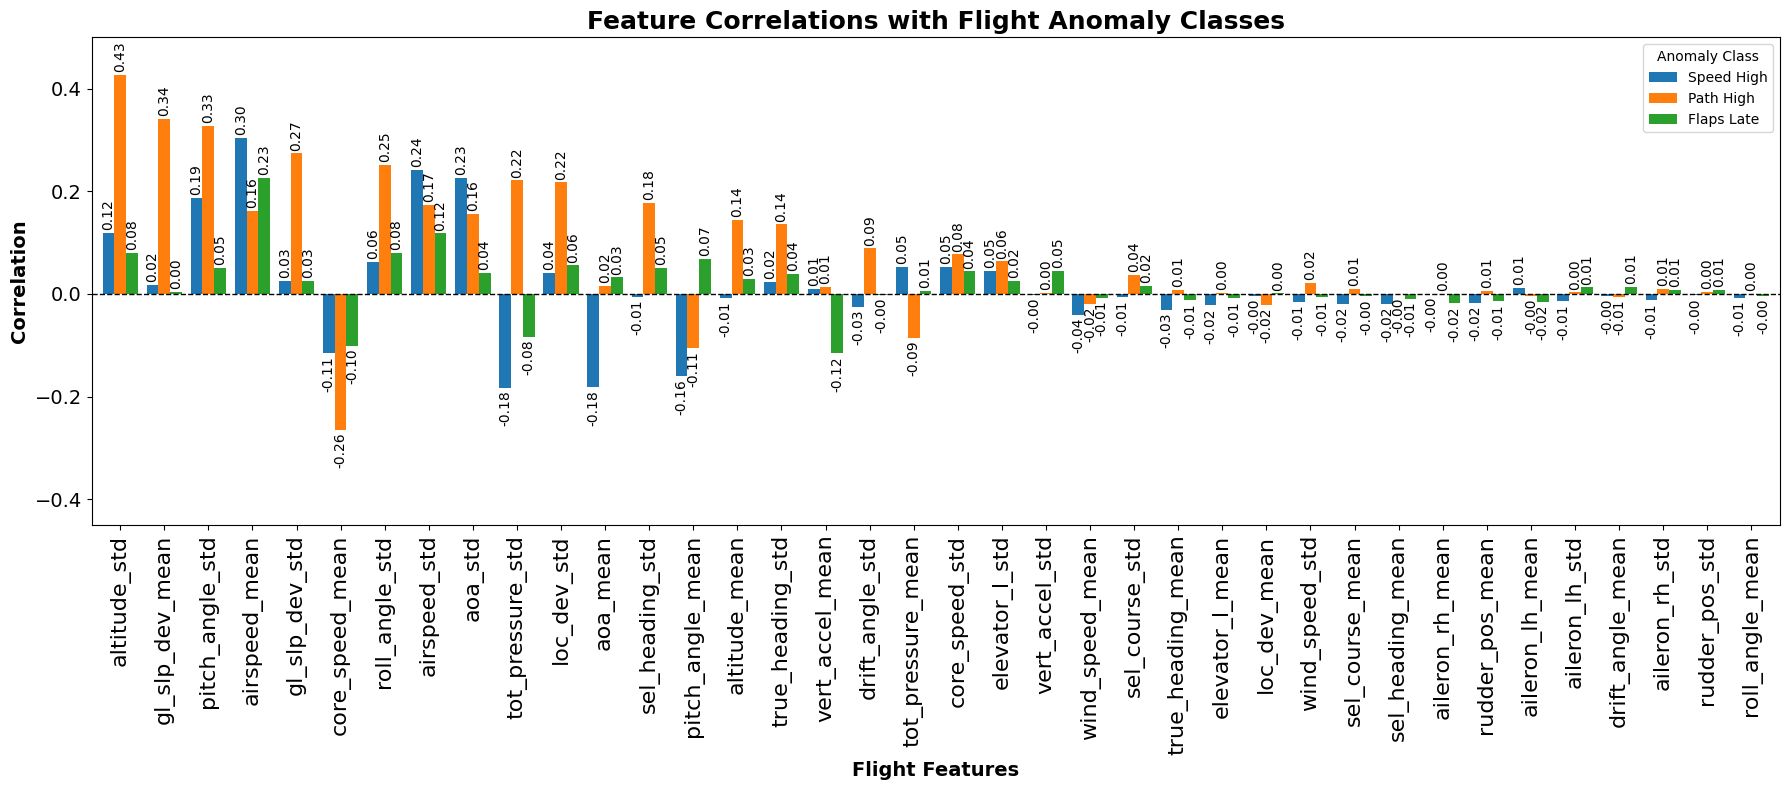

In [ ]:
# Select numerical predictors
X_corr = df_agg_multiclass.drop(columns=['flight_id', 'label', 'arr_arprt', 'arr_arprt_rnwy', 'Flight Anomaly']).select_dtypes(exclude=["object", "category"])

# Calculate class-specific correlations
target_corr_multi = pd.DataFrame({class_name: X_corr.corrwith((df_agg_multiclass['label'] == class_id).astype(int)) for class_id, class_name in class_names.items()})

# Exclude Nominal from the correlation matrix
target_corr_anomalies = target_corr_multi.drop(columns=["Nominal"])

# Sort features by maximum absolute correlation
target_corr_anomalies = target_corr_anomalies.loc[
    target_corr_anomalies.abs().max(axis=1).sort_values(ascending=False).index]

# Plot anomaly-specific correlations
ax = target_corr_anomalies.plot(kind="bar", figsize=(18, 8), width=0.8)

# Reference line at zero
plt.axhline(y=0, color="black", linestyle="--", linewidth=1)

# Add correlation values
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=10, rotation=90)

plt.xlabel("Flight Features", fontsize=14, fontweight='bold')
plt.ylabel("Correlation", fontsize=14, fontweight='bold')
plt.title("Feature Correlations with Flight Anomaly Classes", fontsize=18, fontweight='bold')
plt.xticks(rotation=90, fontsize=16)
plt.yticks(fontsize=14)
plt.ylim(-0.45, 0.5)
plt.legend(title="Anomaly Class")
plt.tight_layout()
plt.show()


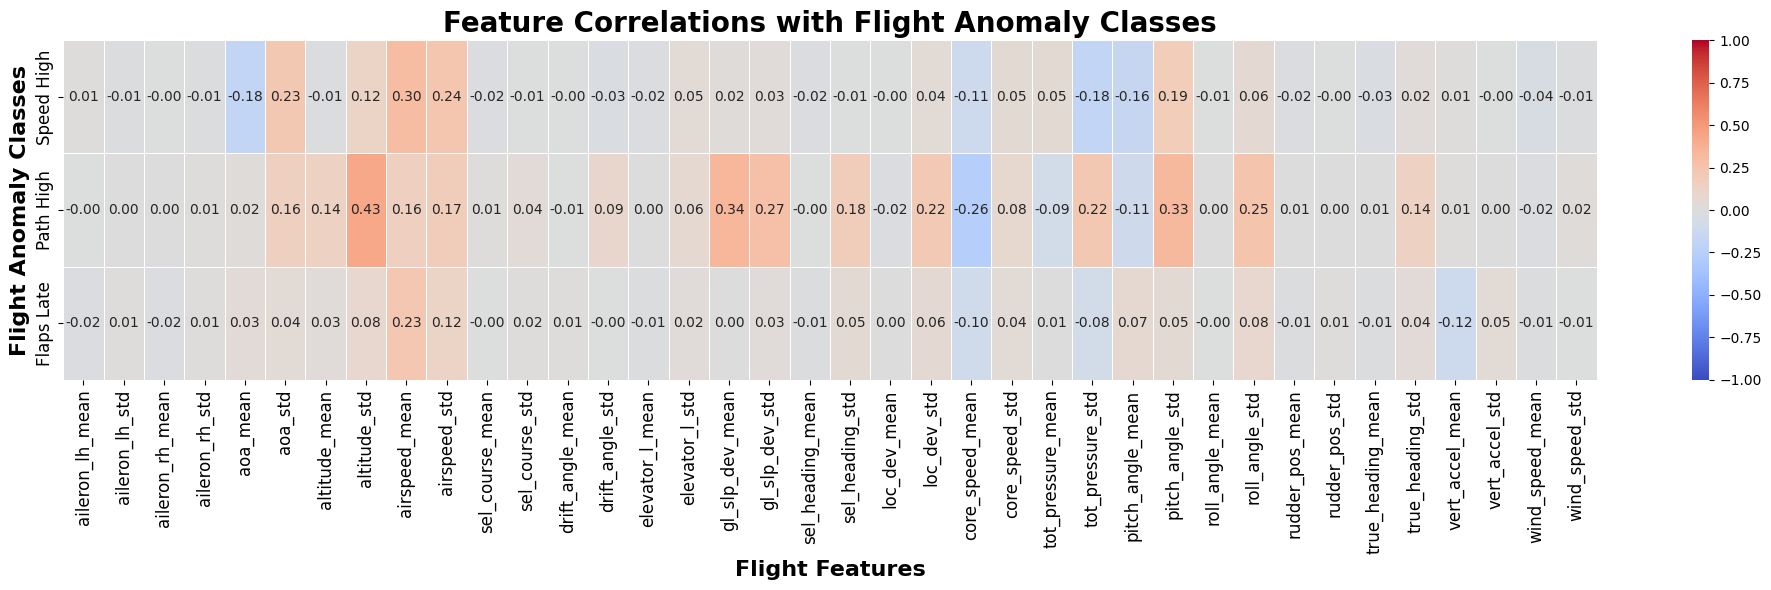

In [ ]:
# Plot correlation heatmap
plt.figure(figsize=(20, 6))
sns.heatmap(target_corr_multi[["Speed High", "Path High", "Flaps Late"]].T, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.xlabel("Flight Features", fontsize=16, fontweight='bold')
plt.ylabel("Flight Anomaly Classes", fontsize=16, fontweight='bold')
plt.title("Feature Correlations with Flight Anomaly Classes", fontsize=20, fontweight='bold')
plt.xticks(rotation=90, fontsize=12)
plt.yticks(rotation=90, fontsize=12)
plt.tight_layout()
plt.show()


**Class-Specific Flight Feature Distributions**


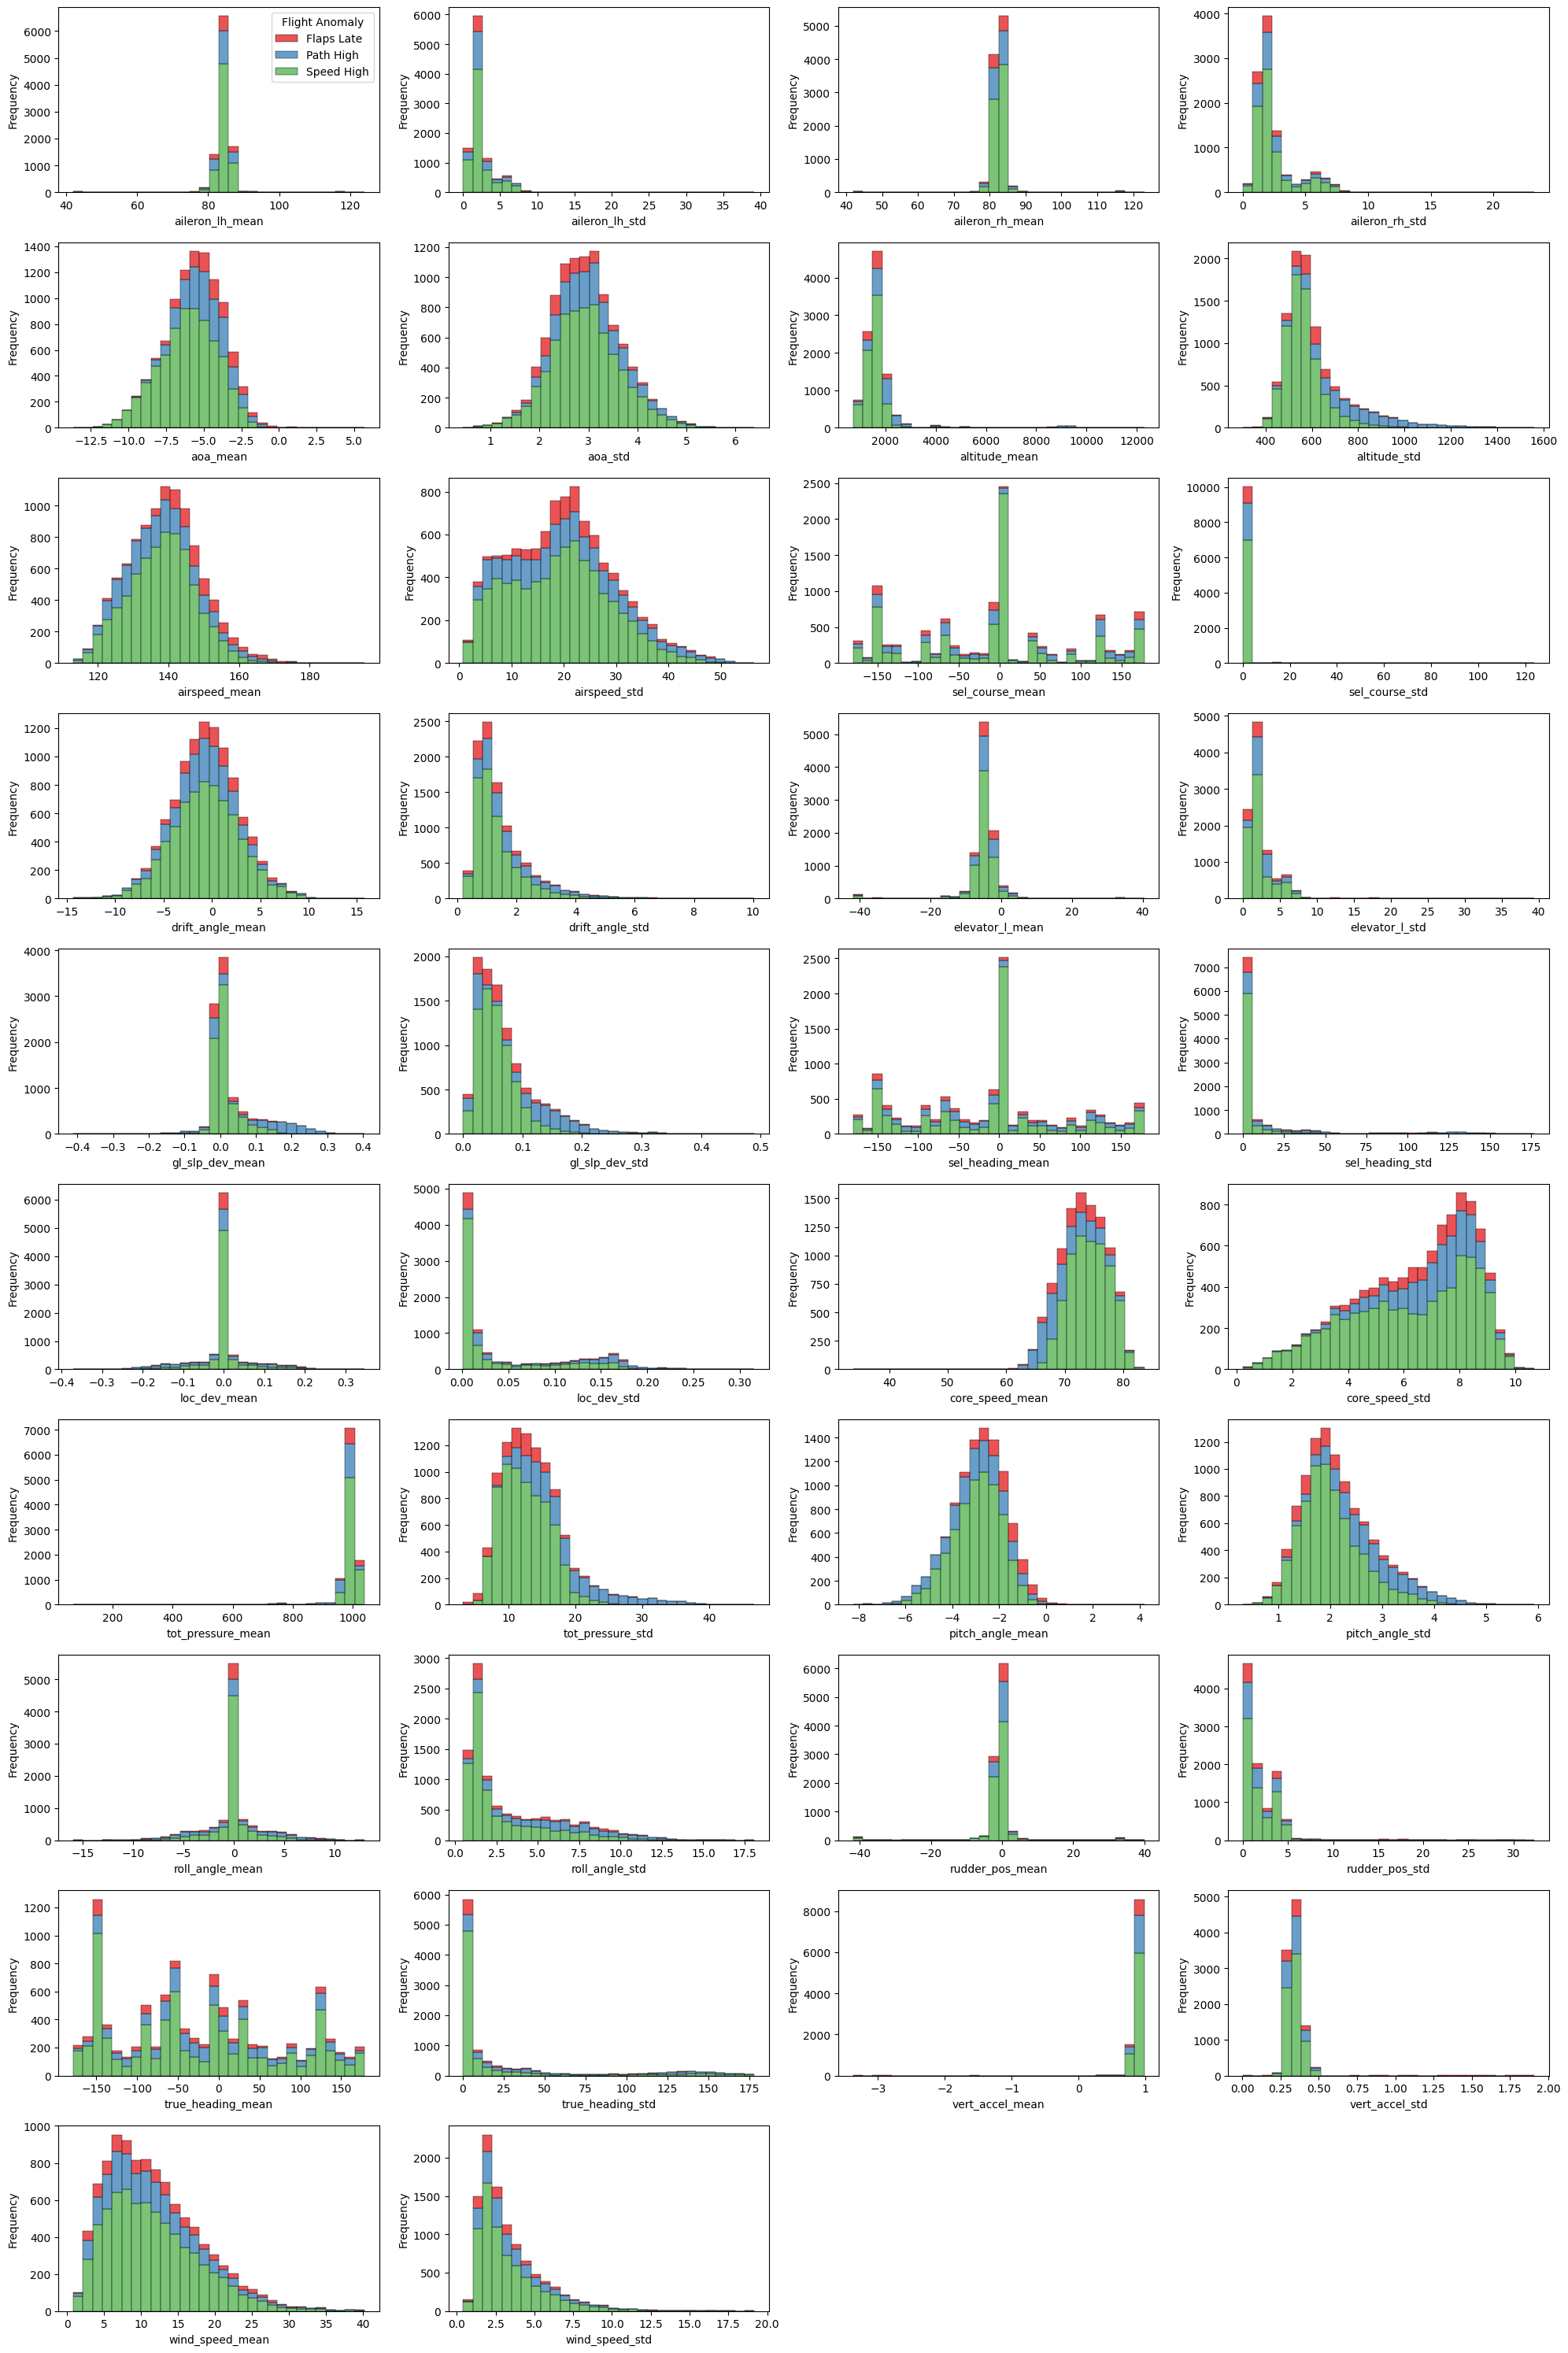

In [ ]:
# Select flight features
features = df_agg_multiclass.columns.drop(['flight_id', 'label', 'arr_arprt', 'arr_arprt_rnwy', 'Flight Anomaly'])
df_histplot = df_agg_multiclass.drop(columns=['flight_id', 'arr_arprt', 'arr_arprt_rnwy'])
df_histplot = df_histplot[df_histplot["label"] != 0].copy()

# Define subplot arrangement
n_cols = 4
n_rows = int(np.ceil(len(features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3), squeeze=False)

# Plot histograms
for i, feature in enumerate(features):
    ax = axes.flat[i]
    sns.histplot(
        data=df_histplot, x=feature, hue="Flight Anomaly",
        hue_order=["Flaps Late", "Path High", "Speed High"],
        multiple="stack", bins=30, palette="Set1",
        edgecolor="black", linewidth=0.3, ax=ax, legend=(i == 0))

    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

# Hide unused subplots
for j in range(len(features), axes.size):
    axes.flat[j].set_visible(False)

plt.tight_layout()
plt.show()


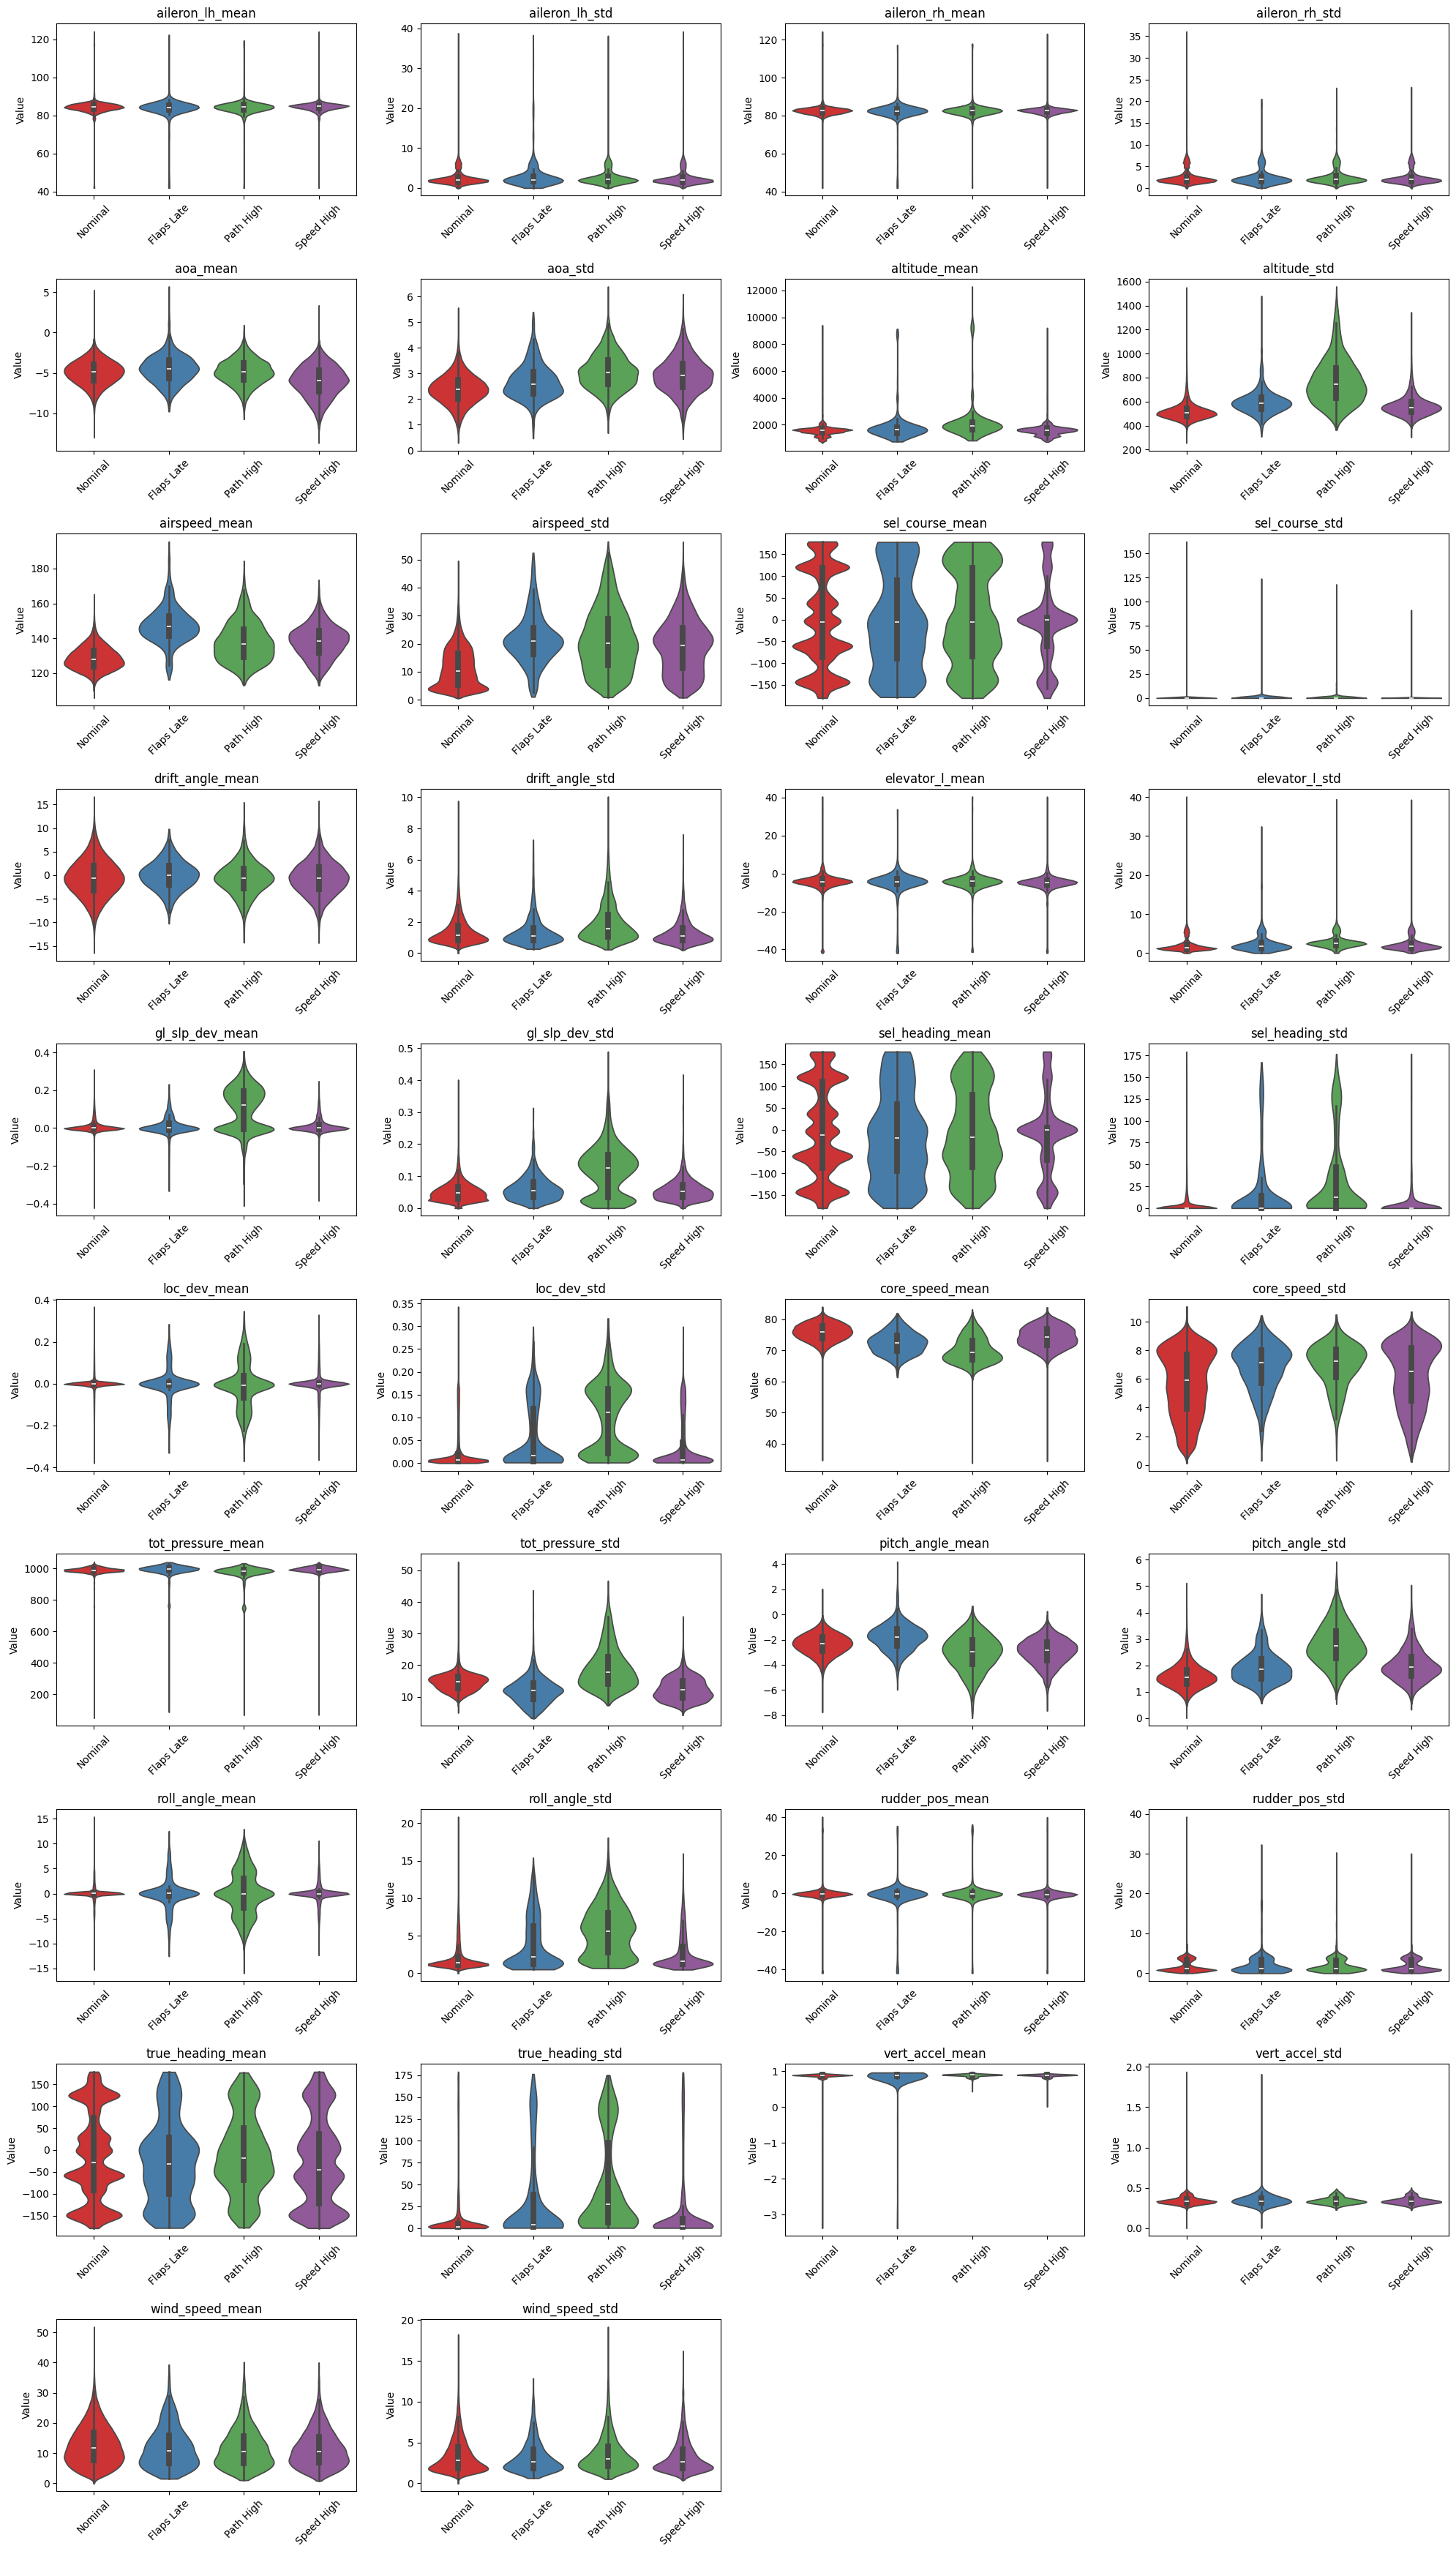

In [ ]:
# Define subplot arrangement
n_cols = 4
n_rows = int(np.ceil(len(features) / n_cols))

# Create fresh subplots
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 3.5),
    squeeze=False
)

df_violinplot = df_agg_multiclass.drop(columns=['flight_id', 'arr_arprt', 'arr_arprt_rnwy'])


# Plot violin plots
for i, feature in enumerate(features):
    ax = axes.flat[i]

    sns.violinplot(
        data=df_violinplot,
        x="Flight Anomaly",
        y=feature,
        order=["Nominal", "Flaps Late", "Path High", "Speed High"],
        hue="Flight Anomaly",
        hue_order=["Nominal", "Flaps Late", "Path High", "Speed High"],
        palette="Set1",
        inner="box",
        cut=0,
        ax=ax,
        legend=False
    )

    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", rotation=45)

# Hide unused subplots
for j in range(len(features), axes.size):
    axes.flat[j].set_visible(False)

plt.tight_layout()
plt.show()


**Top 20 Arrival Airports with Highest Anomaly Rates vs. Overall Average of Anomaly Rates**


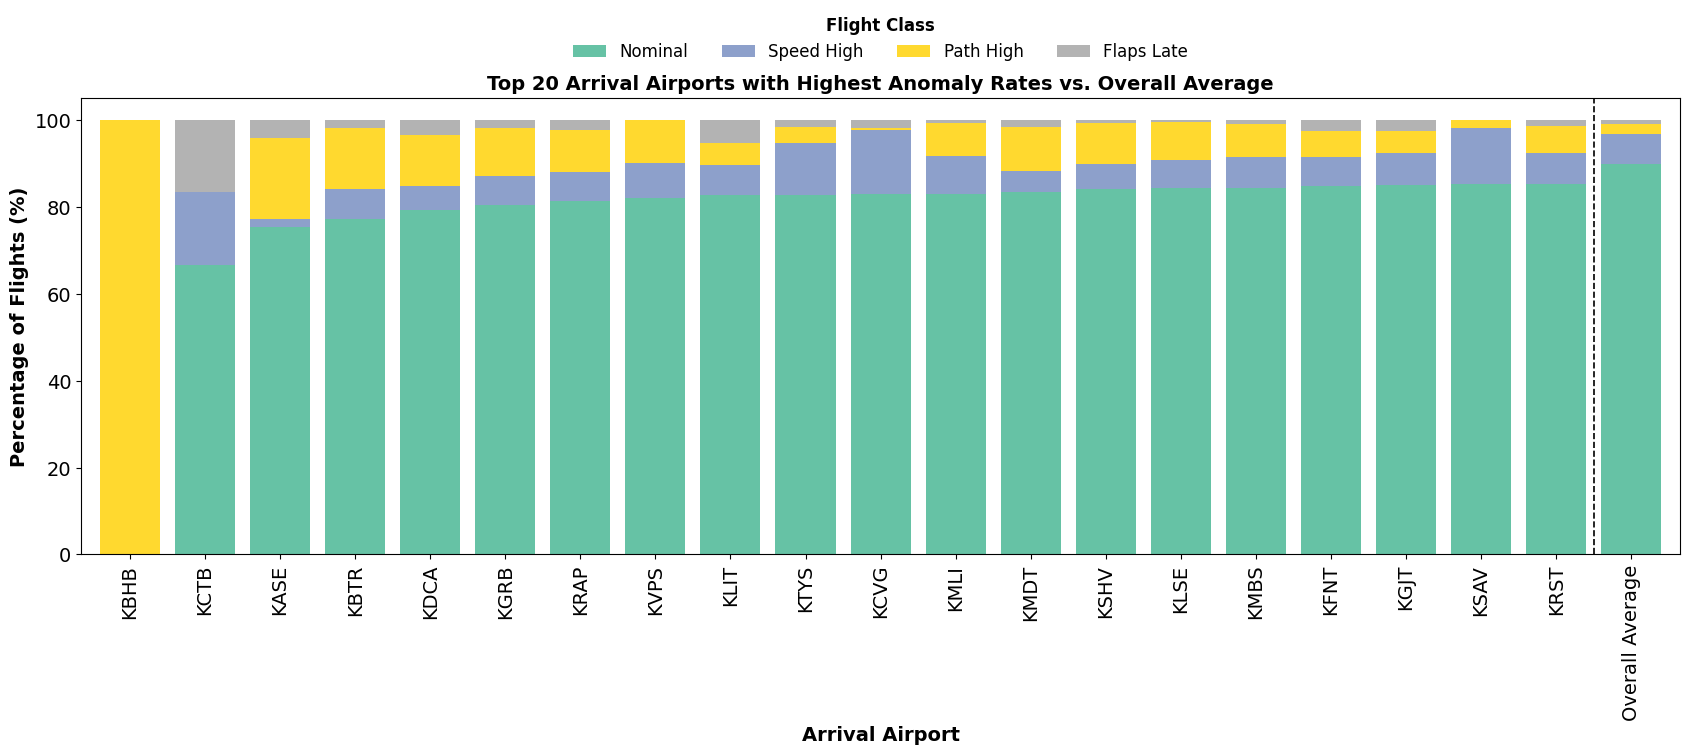

In [ ]:
# Calculate flight counts for each airport and anomaly class
airport_counts = pd.crosstab(df_agg_multiclass["arr_arprt"], df_agg_multiclass["label"]).reindex(columns=[0, 1, 2, 3], fill_value=0)

# Calculate total anomalies (classes 1, 2, and 3)
airport_counts["Total Anomalies"] = airport_counts[[1, 2, 3]].sum(axis=1)

# Calculate anomaly percentage for each airport
airport_counts["Anomaly Rate"] = (airport_counts["Total Anomalies"]/airport_counts[[0, 1, 2, 3]].sum(axis=1)*100)

# Select top 20 airports with the highest anomaly percentages
top_airports = (airport_counts["Anomaly Rate"].nlargest(20).index)

# Select flights from these airports
df_airports = df_agg_multiclass[df_agg_multiclass["arr_arprt"].isin(top_airports)].copy()

# Calculate percentage of each class within each airport
airport_pct = pd.crosstab(df_airports["arr_arprt"], df_airports["label"], normalize="index") * 100

# Ensure all four classes are present and in the correct order
airport_pct = airport_pct.reindex(columns=[0, 1, 2, 3], fill_value=0)

# Rename classes
class_names = {0: "Nominal", 1: "Speed High", 2: "Path High", 3: "Flaps Late"}
airport_pct = airport_pct.rename(columns=class_names)

# Sort airports by anomaly percentage (highest first)
airport_pct = airport_pct.loc[top_airports]

# NEW: Calculate overall percentages for all flights
overall_pct = (
    df_agg_multiclass["label"]
    .value_counts(normalize=True)
    .reindex([0, 1, 2, 3], fill_value=0)
    .mul(100)
    .rename(index=class_names))

# Add overall average as the last bar
airport_pct.loc["Overall Average"] = overall_pct

# Plot
ax = airport_pct.plot(kind="bar", stacked=True, figsize=(17, 7), colormap="Set2", width=0.8)

# Separate the overall average bar from the top 20 airports
ax.axvline(x=len(airport_pct) - 1.5, color="black", linestyle="--", linewidth=1.2)

plt.ylabel("Percentage of Flights (%)", fontsize=14, fontweight="bold")
plt.xlabel("Arrival Airport", fontsize=14, fontweight="bold")
plt.title("Top 20 Arrival Airports with Highest Anomaly Rates vs. Overall Average", fontsize=14, fontweight="bold")
plt.xticks(rotation=90, fontsize=14)
plt.yticks(fontsize=14)
plt.legend(title="Flight Class")
plt.tight_layout()

plt.legend(title="Flight Class", loc="lower center", bbox_to_anchor=(0.5, 1.05), ncol=4, fontsize=12, title_fontsize=12, frameon=False)
plt.gca().get_legend().get_title().set_fontweight("bold")

plt.show()


**Geographic Distribution of Flight Anomalies**


In [ ]:
%pip install plotly airportsdata
import plotly.express as px
import airportsdata

# Calculate flight counts and anomaly rates
airport_counts = pd.crosstab(
    df_agg_multiclass["arr_arprt"],
    df_agg_multiclass["label"]
).reindex(columns=[0, 1, 2, 3], fill_value=0)

# Total flights per airport
airport_counts["Total Flights"] = (airport_counts[[0, 1, 2, 3]].sum(axis=1))

# Total anomalies (classes 1, 2, and 3)
airport_counts["Total Anomalies"] = (airport_counts[[1, 2, 3]].sum(axis=1))

# Calculate anomaly rate (%)
airport_counts["Anomaly Rate"] = (airport_counts["Total Anomalies"]/ airport_counts["Total Flights"]) * 100

# Select top 20 airports by TOTAL anomaly count
top20_map = (airport_counts.nlargest(20, "Total Anomalies").copy().reset_index())

# Get airport coordinates using ICAO codes
airports = airportsdata.load("ICAO")

top20_map["latitude"] = top20_map["arr_arprt"].map(
    lambda x: airports.get(str(x).upper(), {}).get("lat"))

top20_map["longitude"] = top20_map["arr_arprt"].map(
    lambda x: airports.get(str(x).upper(), {}).get("lon"))

# Remove airports with unavailable coordinates
top20_map = top20_map.dropna(subset=["latitude", "longitude"])

# Interactive Plotly map
fig = px.scatter_geo(top20_map,
    lat="latitude",
    lon="longitude",
    size="Anomaly Rate",
    color="Anomaly Rate",
    hover_name="arr_arprt",
    hover_data={
        "Total Flights": True,
        "Total Anomalies": True,
        "Anomaly Rate": ":.2f",
        "latitude": False,
        "longitude": False},

    color_continuous_scale="YlOrRd",

    size_max=40,

    scope="usa",
    projection="albers usa",

    title="Top 20 Arrival Airports with Highest Number of Flight Anomalies",

    labels={
        "Anomaly Rate": "Anomaly Rate (%)",
        "Total Flights": "Total Flights",
        "Total Anomalies": "Total Anomalies"})

# Customize map appearance
fig.update_layout(width=1200, height=700, title_x=0.5, geo=dict(
        showland=True, landcolor="rgb(240, 240, 240)", showcountries=True,
        showsubunits=True, subunitcolor="white", subunitwidth=1,
        showlakes=True, lakecolor="white"), coloraxis_colorbar=dict(title="Anomaly Rate (%)"))


# Display airport codes on map
fig.update_traces(mode="markers+text", text=top20_map["arr_arprt"], textposition="top center",
    textfont=dict(size=10, color="black"), marker=dict(line=dict(width=0.8, color="black"), opacity=0.85))

fig.show()


## **Train-Test Split for Model Development & Evaluation**

To develop and evaluate the prediction performance of the alternative models, the dataset was divided into **training (80%)** and **test (20%)** samples, where the former was used to fit the machine learning models, while the latter was used for testing and evaluating the models' prediction accuracy.
This splitting approach helps prevent overfitting and esnures how well the models are expected to perform on unseen data.

In [6]:
# Split features into the training and test data sets:
X = df_agg_multiclass.drop(columns=['flight_id', 'label', 'Flight Anomaly'], axis=1)
Y = df_agg_multiclass['label']

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.20, stratify=Y, random_state=10)

print("Shape of training samples:",X_train.shape)
print("Shape of test samples:", X_test.shape)


Shape of training samples: (79869, 40)
Shape of test samples: (19968, 40)


### **Target Encoding of Arrival Airport (arr_arprt) & Arrival Airport Runway (arr_arprt_rnwy)**
The arr_arprt (N = 83) and arr_arprt_rnwy features (N = 285) contained a large number of unique categories. Applying one-hot encoding would create many dummy variables, resulting in high dimensionality and sparsity, which can increase computational cost and the risk of overfitting (Galli, S., 2020).

To address this, the above two categorical features were transformed using multiclass target encoding in Scikit-learn. Each category was represented by four numerical values corresponding to the estimated probabilities of the four flight classes, resulting in eight encoded features. Automatic smoothing (smooth="auto") and five-fold cross-fitting (cv=5) were applied to reduce overfitting and target leakage. The encoder was fitted exclusively on the training data and subsequently applied to the test data.


In [7]:
# Initialize multiclass Target Encoder
te = TargetEncoder(target_type="multiclass",  smooth="auto", cv=5, random_state=10)

#  Fit and transform training data
X_train_te = te.fit_transform(X_train[["arr_arprt", "arr_arprt_rnwy"]], y_train)

# Transform test data
X_test_te = te.transform(X_test[["arr_arprt", "arr_arprt_rnwy"]])

# Get the names of the encoded features
encoded_cols = te.get_feature_names_out()

# Convert encoded arrays to DataFrames
X_train_te = pd.DataFrame(X_train_te, columns=encoded_cols, index=X_train.index)

X_test_te = pd.DataFrame(X_test_te, columns=encoded_cols, index=X_test.index)

# Remove original categorical variables and merge the encoded features
cat_cols = ["arr_arprt", "arr_arprt_rnwy"]

X_train_enc = pd.concat([X_train.drop(columns=cat_cols), X_train_te], axis=1)

X_test_enc = pd.concat([X_test.drop(columns=cat_cols), X_test_te], axis=1)

print("Original training shape:", X_train.shape)
print("Encoded training shape:", X_train_enc.shape, '\n')

print("Original testing shape:", X_test.shape)
print("Encoded testing shape:", X_test_enc.shape, '\n')

print("New encoded features:")
print(encoded_cols, '\n')

display(X_train_enc.head())


Original training shape: (79869, 40)
Encoded training shape: (79869, 46) 

Original testing shape: (19968, 40)
Encoded testing shape: (19968, 46) 

New encoded features:
['arr_arprt_0' 'arr_arprt_1' 'arr_arprt_2' 'arr_arprt_3'
 'arr_arprt_rnwy_0' 'arr_arprt_rnwy_1' 'arr_arprt_rnwy_2'
 'arr_arprt_rnwy_3'] 



,aileron_lh_mean,aileron_lh_std,aileron_rh_mean,aileron_rh_std,aoa_mean,aoa_std,altitude_mean,altitude_std,airspeed_mean,airspeed_std,sel_course_mean,sel_course_std,drift_angle_mean,drift_angle_std,elevator_l_mean,elevator_l_std,gl_slp_dev_mean,gl_slp_dev_std,sel_heading_mean,sel_heading_std,loc_dev_mean,loc_dev_std,core_speed_mean,core_speed_std,tot_pressure_mean,tot_pressure_std,pitch_angle_mean,pitch_angle_std,roll_angle_mean,roll_angle_std,rudder_pos_mean,rudder_pos_std,true_heading_mean,true_heading_std,vert_accel_mean,vert_accel_std,wind_speed_mean,wind_speed_std,arr_arprt_0,arr_arprt_1,arr_arprt_2,arr_arprt_3,arr_arprt_rnwy_0,arr_arprt_rnwy_1,arr_arprt_rnwy_2,arr_arprt_rnwy_3
15462,84.693662,1.870317,83.754767,1.900964,-6.364585,2.120303,1480.907834,518.550263,126.641197,5.257146,-145.018500,0.0,4.049653,0.948279,-6.837931,1.198000,0.010654,0.089586,-145.018500,0.0,-0.001350,0.004560,73.758314,4.350752,998.191007,16.854987,-3.043899,1.489315,-0.019164,1.437635,0.007051,1.026619,-154.386627,1.201915,0.903225,0.301928,13.594862,4.436344,0.906951,0.077056,0.008452,0.007540,0.886238,0.098735,0.006404,0.008619
44363,86.220980,3.057785,83.399694,3.082685,-5.656302,2.464198,1626.081356,492.318315,130.249330,7.967312,118.915170,0.0,2.793159,1.167030,-3.376309,1.336513,-0.001129,0.043909,118.915170,0.0,0.005450,0.004550,76.583909,5.116148,980.183889,15.312060,-2.994049,1.326067,0.061648,1.146264,0.389964,0.912897,118.639478,1.122829,0.883113,0.327416,14.800796,2.811853,0.934872,0.050485,0.010906,0.003737,0.933384,0.047913,0.014500,0.004203
9539,83.877132,4.195769,83.153814,2.425485,-5.145557,2.489795,1621.048588,457.827077,125.084365,10.350182,118.915170,0.0,-8.714449,1.642267,-1.107645,1.394995,0.005270,0.037284,118.915170,0.0,0.000229,0.006361,76.464830,6.916609,980.723463,13.775468,-2.428205,1.355228,-0.006868,1.751399,-0.054363,1.304483,128.735305,1.742922,0.893716,0.302632,19.291819,4.051643,0.935012,0.050539,0.010883,0.003566,0.935113,0.047113,0.014990,0.002784
15704,84.847992,2.091028,83.785327,2.279074,-4.776011,2.774827,1724.473950,543.440668,141.583959,19.664649,-61.083540,0.0,2.516568,1.094670,-6.542696,6.456908,0.026639,0.047815,-61.083540,0.0,-0.001972,0.009022,72.992841,6.580006,973.695498,10.254658,-1.810202,2.170815,-0.097782,1.661841,0.565779,1.065278,-61.608749,1.488376,0.886005,0.321643,23.091852,3.312518,0.934669,0.050159,0.011456,0.003716,0.921884,0.060620,0.014037,0.003459
7837,84.244737,1.723623,82.637633,1.766226,-4.833447,2.849707,1221.423924,583.922999,130.769242,9.384239,-2.109358,0.0,-2.090087,1.471174,-40.991156,0.012259,-0.001572,0.000212,-2.109358,0.0,0.004670,0.005688,79.390401,4.324055,998.646314,17.487347,-2.469308,2.209291,0.095203,1.625962,1.504316,0.621179,0.773568,1.776553,0.783566,0.437722,13.703653,4.485099,0.875372,0.102084,0.006371,0.016169,0.833768,0.133958,0.006053,0.026164


## **Feature Scaling**  

To ensure comparability across features and improve model performance, this project applied **standardization**, which rescales the input features to have a mean of 0 and a standard deviation of 1. This approach allows the model to assess the relative importance of features on a consistent scale.  


In [8]:
scaler = StandardScaler()
X_train_scld = scaler.fit_transform(X_train_enc)
X_test_scld  = scaler.transform(X_test_enc)

print("X_train_scld:")
print(X_train_scld)
print()
print("X_test_scld:")
print(X_test_scld)


X_train_scld:
[[ 0.09730547 -0.30473777  0.26537459 ...  0.98825027 -0.33432881
  -0.08085348]
 [ 0.37419242  0.09640597  0.19001114 ... -0.76670465 -0.15569641
  -0.56635151]
 [-0.05072285  0.48083335  0.13782383 ... -0.79432591 -0.14487588
  -0.72235762]
 ...
 [ 0.28374342 -0.49519507 -0.13391345 ...  0.9622111  -0.32590912
  -0.03395239]
 [ 0.03578546 -0.40489531  0.29671948 ... -0.68227061 -0.3326503
  -0.63988818]
 [ 0.04725959  1.269972   -0.21378199 ...  2.87619522 -0.41500632
   1.2302974 ]]

X_test_scld:
[[-0.09898399 -0.16552697  0.46831586 ... -0.18733603 -0.32859497
  -0.2722809 ]
 [ 0.35133669  0.0600951   0.01051739 ... -0.95916339 -0.28624746
  -0.71390946]
 [-0.12065731 -0.3480112   0.04205216 ... -0.72806497 -0.3279624
   0.1954446 ]
 ...
 [ 0.09684192 -0.05150958  0.31772469 ...  0.9456235  -0.32600854
   0.06771131]
 [-0.01437638 -0.54409775  0.74596949 ...  0.49313091  0.3512143
   0.20880522]
 [-0.4583458   1.3091952   0.474205   ...  0.9456235  -0.32600854
   0.06

## **Feature Selection**

When developing machine learning models, not all features (predictors) are necessarily associated with the target variable. Including redundant or irrelevant predictors may increase the risk of overfitting and add unnecessary computational complexity. Therefore, feature selection was performed to retain the most relevant predictors before model development.

In this project, **Boruta** was used for feature selection. An **ExtraTreesClassifier** was used as the base estimator because of its ability to efficiently capture nonlinear relationships and interaction effects among predictors. Boruta identifies relevant features by comparing the importance of the original features with that of randomly generated **shadow features**.

Because the target variable (`label`) is highly imbalanced, `class_weight='balanced'` was applied to the ExtraTreesClassifier to give greater consideration to the minority class during the feature-selection process.

Importantly, to avoid **data leakage**, Boruta was fitted using only the training dataset. The selected features were then applied to both the training and test datasets before developing and evaluating the machine learning models.

In [9]:
!pip install boruta
from boruta import BorutaPy

selector = ExtraTreesClassifier(n_estimators=500, random_state=1, n_jobs=-1, class_weight='balanced')
boruta = BorutaPy(selector, n_estimators='auto', random_state=1)

boruta.fit(X_train_scld, y_train)

selected_features = X_train_enc.columns[boruta.support_]

print()
print("Selected features:", selected_features)
print()
print("Dropped features:", X_train_enc.columns[~boruta.support_], '\n')

# Boolean mask
mask = boruta.support_

# Apply mask
X_train_selected = X_train_scld[:, mask]
X_test_selected  = X_test_scld[:, mask]

print("Shapes after selection:", X_train_selected.shape, X_test_selected.shape, y_train.shape, y_test.shape)



Selected features: Index(['aoa_mean', 'aoa_std', 'altitude_mean', 'altitude_std', 'airspeed_mean',
       'airspeed_std', 'sel_course_mean', 'drift_angle_std', 'gl_slp_dev_mean',
       'gl_slp_dev_std', 'sel_heading_mean', 'sel_heading_std', 'loc_dev_std',
       'core_speed_mean', 'core_speed_std', 'tot_pressure_mean',
       'tot_pressure_std', 'pitch_angle_mean', 'pitch_angle_std',
       'roll_angle_mean', 'roll_angle_std', 'true_heading_mean',
       'true_heading_std', 'vert_accel_mean', 'vert_accel_std', 'arr_arprt_0',
       'arr_arprt_1', 'arr_arprt_2', 'arr_arprt_rnwy_0', 'arr_arprt_rnwy_1',
       'arr_arprt_rnwy_2'],
      dtype='object')

Dropped features: Index(['aileron_lh_mean', 'aileron_lh_std', 'aileron_rh_mean',
       'aileron_rh_std', 'sel_course_std', 'drift_angle_mean',
       'elevator_l_mean', 'elevator_l_std', 'loc_dev_mean', 'rudder_pos_mean',
       'rudder_pos_std', 'wind_speed_mean', 'wind_speed_std', 'arr_arprt_3',
       'arr_arprt_rnwy_3'],
      dtyp

###**Selected & Dropped Features**
**Selected features:**

['aoa_mean', 'aoa_std', 'altitude_mean', 'altitude_std', 'airspeed_mean',
       'airspeed_std', 'sel_course_mean', 'drift_angle_std', 'gl_slp_dev_mean',
       'gl_slp_dev_std', 'sel_heading_mean', 'sel_heading_std', 'loc_dev_std',
       'core_speed_mean', 'core_speed_std', 'tot_pressure_mean',
       'tot_pressure_std', 'pitch_angle_mean', 'pitch_angle_std',
       'roll_angle_mean', 'roll_angle_std', 'true_heading_mean',
       'true_heading_std', 'vert_accel_mean', 'vert_accel_std', 'arr_arprt_0',
       'arr_arprt_1', 'arr_arprt_2', 'arr_arprt_rnwy_0', 'arr_arprt_rnwy_1',
       'arr_arprt_rnwy_2']

**Dropped features:**

['aileron_lh_mean', 'aileron_lh_std', 'aileron_rh_mean',
       'aileron_rh_std', 'sel_course_std', 'drift_angle_mean',
       'elevator_l_mean', 'elevator_l_std', 'loc_dev_mean', 'rudder_pos_mean',
       'rudder_pos_std', 'wind_speed_mean', 'wind_speed_std', 'arr_arprt_3',
       'arr_arprt_rnwy_3']

## **Handling Class Imbalance**

The **anomaly class** represents only about **10%** of all observations in the target variable, resulting in **class imbalance**. Different strategies were adopted depending on the algorithm used.

For **XGBoost** and **LightGBM**, two approaches were evaluated. First, the models were trained using the **original training dataset**, with class-imbalance parameters included in the hyperparameter optimization (`scale_pos_weight` for XGBoost and `class_weight` for LightGBM). Second, separate models were developed using **SMOTE-resampled training data**. SMOTE (Synthetic Minority Oversampling Technique) generates synthetic minority-class observations to increase the representation of anomalous flights. SMOTE was applied **exclusively to the training data** to prevent data leakage and preserve an unbiased evaluation on the held-out test set.

For **Balanced Random Forest (BRF)**, the original training dataset was used without SMOTE because BRF addresses class imbalance internally through balanced sampling during model training.

For the **Neural Network (NN)** model, SMOTE-based resampling was not evaluated due to the **additional computational cost and training time** associated with hyperparameter optimization on the enlarged training dataset. Instead, the NN model was trained using the **original imbalanced training dataset** to maintain computational efficiency.

During **hyperparameter optimization** of models using SMOTE-resampled dataset, SMOTE was incorporated into a **cross-validation pipeline** to prevent data leakage. This ensured that synthetic observations were generated **only from the training portion of each cross-validation fold**, while the corresponding validation portion retained its original class distribution. Applying SMOTE before cross-validation could introduce closely related observations into both training and validation folds, potentially producing overly optimistic performance estimates. Therefore, the pipeline enabled a more reliable and unbiased comparison of hyperparameter configurations using **macro-averaged F1-score (macro-F1)**.


In [10]:
smote = SMOTE(random_state=100)
X_train_smote, y_train_smote = smote.fit_resample(X_train_selected, y_train)
print("Shapes of Training Samples After SMOTE:", X_train_smote.shape, y_train_smote.shape)


Shapes of Training Samples After SMOTE: (286920, 31) (286920,)


# **STEP 3: MACHINE LEARNING MODEL DEVELOPMENT AND EVALUATION**

To detect anomalous flights, six candidate machine learning models were developed and evaluated:

- **Balanced Random Forest (BRF)**
- **XGBoost (XGB)**
- **Light Gradient Boosting Machine (LightGBM)**
- **Artificial Neural Network (ANN)**

Each model was developed using the same set of features selected through the **Boruta feature-selection method** and evaluated on the same unseen test dataset. Model performance was assessed using **macro-averaged** **Recall**, **Precision**, and **F1-score**, with particular emphasis on **macro F1-score** due to the class imbalance in the target variable.

During hyperparameter optimization for each model, **three-fold stratified cross-validation** (`n_splits=3`) was employed instead of the commonly used five-fold approach to **reduce computational complexity and training time**.

Detailed development, hyperparameter optimization, and evaluation procedures for each candidate model are presented in the following subsections.


## **(1) Balanced Random Forest Classifier (BRF)**

### **Hyperparameter Optimization**


In [ ]:
# Define hyperparameter grid
param_grid_brf = {
    "n_estimators": [100, 200, 500],
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2"]
}


# Balanced Random Forest model
brf = BalancedRandomForestClassifier(random_state=100, n_jobs=-1, sampling_strategy="all",  replacement=True, bootstrap=False)


# Randomized search
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=10)
search_brf = RandomizedSearchCV(estimator=brf, param_distributions=param_grid_brf, n_iter=20, scoring="f1_macro",
                                cv=cv, random_state=10, n_jobs=1, refit=True)

# Fit on original training data, not SMOTE-applied training data
search_brf.fit(X_train_selected, y_train)

# Results
score_brf = pd.DataFrame(search_brf.cv_results_)
scores_brf = score_brf[["params", "mean_test_score", "rank_test_score"]]

score_brf = pd.DataFrame(search_brf.cv_results_)

print("Best parameters:", search_brf.best_params_, '\n')
print("Best CV Macro-F1:", round(search_brf.best_score_, 3), '\n')


Best parameters: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None} 

Best CV Macro-F1: 0.558 



### **Model Training and Performance Evaluation**

In [ ]:
# Fit Balanced Random Forest with optimal hyperparameters
brf_optimal = BalancedRandomForestClassifier(n_estimators=200, min_samples_leaf=2, max_features='sqrt', max_depth= None, random_state=10, n_jobs=-1)
brf_optimal.fit(X_train_selected, y_train)

# Predicted probabilities and labels
y_prob_brf = brf_optimal.predict_proba(X_test_selected)
y_pred_brf = brf_optimal.predict(X_test_selected)

# Classification report
print("Balanced Random Forest - Multiclass Classification")
print(classification_report(y_test, y_pred_brf,labels=[0, 1, 2, 3], target_names=list(class_names.values()), zero_division=0), '\n')

# Macro precision, recall, and F1:
precision_brf = precision_score(y_test, y_pred_brf, average="macro", zero_division=0)
recall_brf = recall_score(y_test, y_pred_brf, average="macro", zero_division=0)
f1_brf = f1_score(y_test, y_pred_brf, average="macro", zero_division=0)

# Predicted probabilities for all four classes
y_prob_brf = brf_optimal.predict_proba(X_test_selected)

# Convert actual labels to binary indicators
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])

# Calculate Macro Average Precision
ap_brf = average_precision_score(y_test_bin, y_prob_brf, average="macro")
print("Macro Average Precision (AP):", round(ap_brf, 3))


Balanced Random Forest - Multiclass Classification
              precision    recall  f1-score   support

     Nominal       0.99      0.84      0.91     17933
  Speed High       0.43      0.84      0.57      1403
   Path High       0.30      0.92      0.46       441
  Flaps Late       0.22      0.80      0.34       191

    accuracy                           0.84     19968
   macro avg       0.49      0.85      0.57     19968
weighted avg       0.93      0.84      0.87     19968
 

Macro Average Precision (AP): 0.745


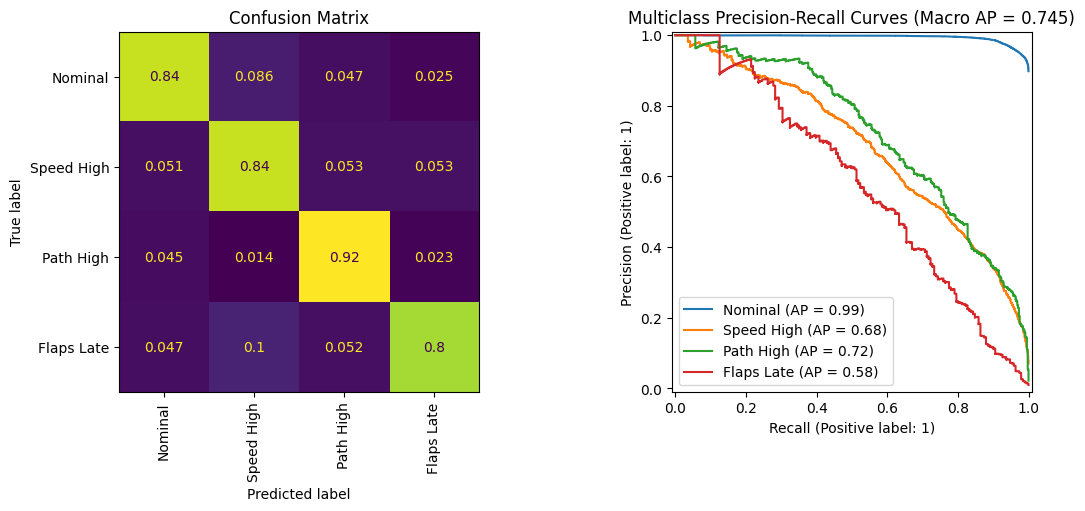

In [ ]:
# Evaluate Model Performance: Confusion Matrix and Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1, 1.6]}, layout="constrained")

classes = [0, 1, 2, 3]

# 1. Confusion Matrix
cm_brf = confusion_matrix(y_test, y_pred_brf, labels=classes, normalize="true")

disp_cm_brf = ConfusionMatrixDisplay(confusion_matrix=cm_brf, display_labels=[class_names[c] for c in classes])

disp_cm_brf.plot(ax=axes[0], colorbar=False, xticks_rotation=90)
axes[0].set_title("Confusion Matrix")

# 2. Multiclass Precision-Recall Curves
y_test_bin = label_binarize(y_test, classes=classes)

prob_indices = [list(brf_optimal.classes_).index(c) for c in classes]
y_prob_ordered = y_prob_brf[:, prob_indices]

for i, cls in enumerate(classes):
    PrecisionRecallDisplay.from_predictions(
        y_test_bin[:, i],
        y_prob_ordered[:, i],
        ax=axes[1],
        name=class_names[cls])

# Macro Average Precision
ap_brf = average_precision_score(y_test_bin, y_prob_ordered, average="macro")

axes[1].set_title(f"Multiclass Precision-Recall Curves (Macro AP = {ap_brf:.3f})")

plt.show()


## **(2) XGBoost Classifier**

Two XGBoost models were developed and compared using two different approaches to address the class imbalance in the dataset:

- **Original Dataset:** XGBoost was trained on the original training data, with `scale_pos_weight` included in the hyperparameter optimization to evaluate class-weight adjustment.
- **SMOTE-Resampled Dataset:** XGBoost was trained using SMOTE-resampled training data to balance the class distribution before model training.

### **(2-1) XGBoost using Original Dataset**


#### **Hyperparameter Optimization**

In [ ]:
# Define the hyperparameter grid
param_grid_xgb = {
    'learning_rate': [0.03, 0.05, 0.07, 0.1],
    'max_depth': [4, 6, 8],
    'n_estimators': [300, 500, 1000]}

# Define multiclass XGBoost model
xgb_model = xgb.XGBClassifier(objective="multi:softprob", num_class=4, eval_metric="mlogloss", random_state=10, n_jobs=-1, tree_method="hist")

# Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=10)

# RandomizedSearchCV
search_xgb = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid_xgb,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    random_state=10,
    n_jobs=1,
    refit=True)

# Fit the model
search_xgb.fit(X_train_selected, y_train)

# Best results
print("Best Parameters:")
print(search_xgb.best_params_, '\n')
print("Best Cross-Validation Macro F1:", round(search_xgb.best_score_, 3))


Best Parameters:
{'n_estimators': 1000, 'max_depth': 4, 'learning_rate': 0.05} 

Best Cross-Validation Macro F1: 0.782


#### **Model Training and Performance Evaluation**

In [11]:
# Initialize XGBoost with optimal hyperparameters
xgb_optimal = xgb.XGBClassifier(objective="multi:softprob", num_class=4, eval_metric="mlogloss", learning_rate=0.05,
                                max_depth=4, n_estimators=1000, random_state=10, tree_method="hist")

# Fit the optimal XGBoost classifier
xgb_optimal.fit(X_train_selected, y_train)

# Predicted probabilities and labels
y_prob_xgb = xgb_optimal.predict_proba(X_test_selected)
y_pred_xgb = xgb_optimal.predict(X_test_selected)

# Classification report
print("XGBoost - Multiclass Classification")
print(classification_report(
        y_test,
        y_pred_xgb,
        labels=[0, 1, 2, 3],
        target_names=list(class_names.values()),
        zero_division=0), '\n')

# Macro precision, recall, and F1
precision_xgb = precision_score(y_test, y_pred_xgb, average="macro", zero_division=0)

recall_xgb = recall_score(y_test, y_pred_xgb, average="macro", zero_division=0)

f1_xgb = f1_score(y_test, y_pred_xgb, average="macro", zero_division=0)

# Convert actual labels to binary indicators
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])

# Calculate Macro Average Precision
ap_xgb = average_precision_score(y_test_bin, y_prob_xgb, average="macro")

# AP for each individual class
ap_per_class_xgb = average_precision_score(y_test_bin, y_prob_xgb, average=None)

# Calculate anomaly-only Macro AP (classes 1, 2, 3)
anomaly_ap_xgb = ap_per_class_xgb[1:].mean()

# Display results
print("Macro Precision:", round(precision_xgb, 3))
print("Macro Recall:", round(recall_xgb, 3))
print("Macro F1:", round(f1_xgb, 3))
print("Macro Average Precision (AP):", round(ap_xgb, 3))
print("Anomaly-only Macro AP:", round(anomaly_ap_xgb, 3))


XGBoost - Multiclass Classification
              precision    recall  f1-score   support

     Nominal       0.97      0.99      0.98     17933
  Speed High       0.86      0.73      0.79      1403
   Path High       0.81      0.68      0.74       441
  Flaps Late       0.87      0.63      0.73       191

    accuracy                           0.96     19968
   macro avg       0.88      0.76      0.81     19968
weighted avg       0.96      0.96      0.96     19968
 

Macro Precision: 0.88
Macro Recall: 0.757
Macro F1: 0.811
Macro Average Precision (AP): 0.876
Anomaly-only Macro AP: 0.835


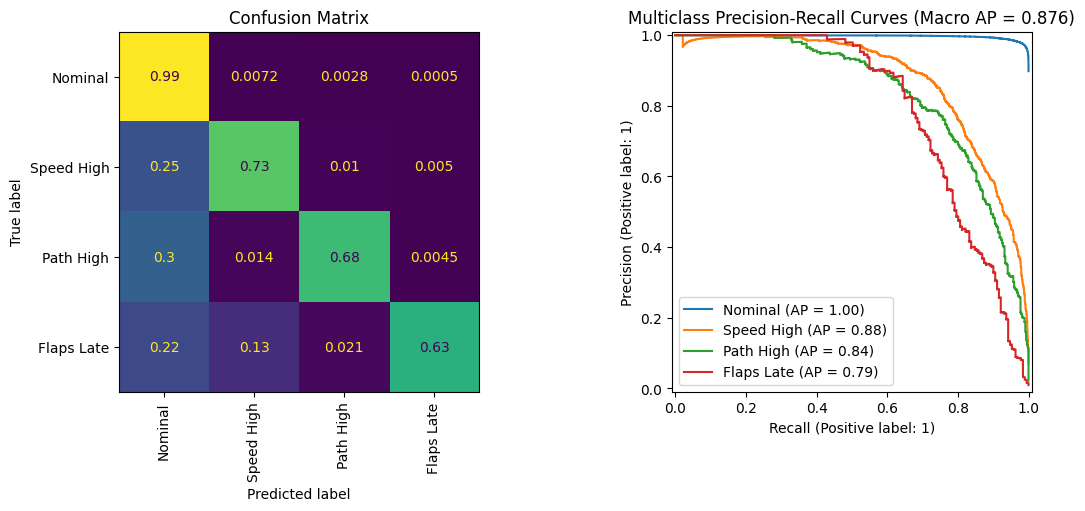

In [12]:
# Confusion Matrix and Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1, 1.6]}, layout="constrained")

classes = [0, 1, 2, 3]

# 1. Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=classes, normalize="true")

disp_cm_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=[class_names[c] for c in classes])

disp_cm_xgb.plot(ax=axes[0], colorbar=False, xticks_rotation=90)

axes[0].set_title("Confusion Matrix")

# 2. Multiclass Precision-Recall Curves
y_test_bin = label_binarize(y_test, classes=classes)

prob_indices = [list(xgb_optimal.classes_).index(c) for c in classes]

y_prob_ordered = y_prob_xgb[:, prob_indices]

for i, cls in enumerate(classes):
    PrecisionRecallDisplay.from_predictions(
        y_test_bin[:, i],
        y_prob_ordered[:, i],
        ax=axes[1],
        name=class_names[cls])

# Macro Average Precision
ap_xgb = average_precision_score(y_test_bin, y_prob_ordered, average="macro")

axes[1].set_title(f"Multiclass Precision-Recall Curves (Macro AP = {ap_xgb:.3f})")

plt.show()


### **(2-2) XGBoost with SMOTE Resampling**

#### **Hyperparameter Optimization**

In [ ]:
# Create SMOTE + XGBoost pipeline
pipeline_xgb = Pipeline([
    ('smote', SMOTE(random_state=10)),
    ('xgb', xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=4,
        eval_metric="mlogloss",
        random_state=10,
        n_jobs=-1,
        tree_method="hist"
    ))])

# Define hyperparameter distributions
param_grid_xgb = {
    'xgb__learning_rate': [0.03, 0.05, 0.07, 0.1],
    'xgb__max_depth': [4, 6, 8],
    'xgb__n_estimators': [300, 500, 1000]
}

# Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=10)

# RandomizedSearchCV
search_xgb_smote = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=param_grid_xgb,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    random_state=10,
    n_jobs=1,
    refit=True,
    error_score="raise")

# Fit on ORIGINAL training data: SMOTE is applied only within each CV training fold
search_xgb_smote.fit(X_train_selected, y_train)

# Best parameters and CV score
print("Best Parameters:")
print(search_xgb_smote.best_params_)
print("\nBest Cross-Validation Macro F1:", round(search_xgb_smote.best_score_, 3))


Best Parameters:
{'xgb__n_estimators': 500, 'xgb__max_depth': 8, 'xgb__learning_rate': 0.1}

Best Cross-Validation Macro F1: 0.749


#### **Model Training and Performance Evaluation**

In [ ]:
# Fit the XGB Classifier using the optimal hyperparameters, on the SMOTE-resampled training data
xgb_optimal_SMOTE = xgb.XGBClassifier(objective="multi:softprob", num_class=4, eval_metric="mlogloss", learning_rate=0.1,
                                max_depth=8, n_estimators=500, random_state=10, tree_method="hist")

xgb_optimal_SMOTE.fit(X_train_smote, y_train_smote)

# Predicted probabilities and labels on ORIGINAL test data
y_prob_xgb_smote = xgb_optimal_SMOTE.predict_proba(X_test_selected)
y_pred_xgb_smote = xgb_optimal_SMOTE.predict(X_test_selected)

# Classification report
classes = [0, 1, 2, 3]

print("XGBoost with SMOTE - Multiclass Classification")
print(classification_report(y_test, y_pred_xgb_smote, labels=classes,
        target_names=[class_names[c] for c in classes],
        zero_division=0), '\n')

# Macro Precision, Recall, and F1
precision_xgb_smote = precision_score(
    y_test, y_pred_xgb_smote,
    labels=classes,
    average="macro",
    zero_division=0)

recall_xgb_smote = recall_score(
    y_test, y_pred_xgb_smote,
    labels=classes,
    average="macro",
    zero_division=0)

f1_xgb_smote = f1_score(
    y_test, y_pred_xgb_smote,
    labels=classes,
    average="macro",
    zero_division=0)

# Convert actual labels to binary indicators
y_test_bin = label_binarize(y_test, classes=classes)

# Ensure predicted probabilities follow the correct class order
prob_indices = [list(xgb_optimal_SMOTE.classes_).index(c) for c in classes]

y_prob_ordered = y_prob_xgb_smote[:, prob_indices]

# Calculate overall Macro Average Precision
ap_xgb_smote = average_precision_score(y_test_bin, y_prob_ordered, average="macro")

# Calculate Average Precision for each class
ap_per_class_xgb_smote = average_precision_score(y_test_bin, y_prob_ordered, average=None)

# Calculate Anomaly-only Macro AP (classes 1, 2, 3)
anomaly_ap_xgb_smote = np.mean(ap_per_class_xgb_smote[1:])

# Display results
print("Macro Precision:", round(precision_xgb_smote, 3))
print("Macro Recall:", round(recall_xgb_smote, 3))
print("Macro F1:", round(f1_xgb_smote, 3))
print("Macro Average Precision (AP):", round(ap_xgb_smote, 3))
print("Anomaly-only Macro AP:", round(anomaly_ap_xgb_smote, 3))

# Display individual class AP values
print("\nAverage Precision by Class:")
for cls, ap in zip(classes, ap_per_class_xgb_smote):
    print(f"{class_names[cls]}: {ap:.3f}")


XGBoost with SMOTE - Multiclass Classification
              precision    recall  f1-score   support

     Nominal       0.99      0.91      0.95     17933
  Speed High       0.46      0.88      0.61      1403
   Path High       0.63      0.83      0.71       441
  Flaps Late       0.59      0.72      0.65       191

    accuracy                           0.90     19968
   macro avg       0.67      0.83      0.73     19968
weighted avg       0.94      0.90      0.91     19968
 

Macro Precision: 0.666
Macro Recall: 0.833
Macro F1: 0.728
Macro Average Precision (AP): 0.847
Anomaly-only Macro AP: 0.798

Average Precision by Class:
Nominal: 0.995
Speed High: 0.820
Path High: 0.831
Flaps Late: 0.743


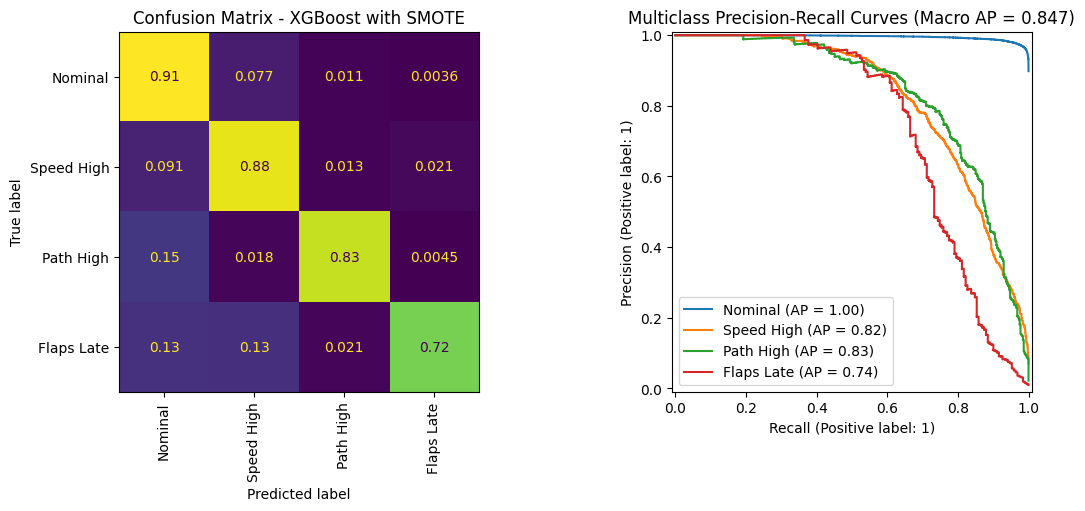

In [ ]:
# Confusion Matrix and Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1, 1.6]}, layout="constrained")

classes = [0, 1, 2, 3]

# 1. Confusion Matrix
cm_xgb_smote = confusion_matrix(y_test, y_pred_xgb_smote, labels=classes, normalize="true")

disp_cm_xgb_smote = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb_smote,
    display_labels=[class_names[c] for c in classes])

disp_cm_xgb_smote.plot(ax=axes[0], colorbar=False, xticks_rotation=90)

axes[0].set_title("Confusion Matrix - XGBoost with SMOTE")

# 2. Multiclass Precision-Recall Curves
y_test_bin = label_binarize(y_test, classes=classes)

prob_indices = [list(xgb_optimal_SMOTE.classes_).index(c) for c in classes]

y_prob_ordered_smote = y_prob_xgb_smote[:, prob_indices]

for i, cls in enumerate(classes):
    PrecisionRecallDisplay.from_predictions(
        y_test_bin[:, i],
        y_prob_ordered_smote[:, i],
        ax=axes[1],
        name=class_names[cls]    )

# 3. Macro Average Precision
ap_xgb_smote = average_precision_score(y_test_bin, y_prob_ordered_smote, average="macro")

axes[1].set_title(f"Multiclass Precision-Recall Curves (Macro AP = {ap_xgb_smote:.3f})")

plt.show()



### **Comparison of XGBoost With and Without SMOTE Resampling**

The performance of **XGBoost trained on the original imbalanced dataset** was compared with **XGBoost using SMOTE-resampled training data** for multiclass flight anomaly detection. Both models were evaluated on the same held-out test dataset of **19,968 flights** across four classes: Nominal, Speed High, Path High, and Flaps Late.

#### **Overall Model Performance**

| Evaluation Metric | XGBoost without SMOTE | XGBoost with SMOTE |
|---|---:|---:|
| Accuracy | **0.96** | 0.90 |
| Macro Precision | **0.880** | 0.666 |
| Macro Recall | 0.757 | **0.833** |
| Macro F1-score | **0.811** | 0.728 |
| Macro Average Precision (AP) | **0.876** | 0.847 |
| Anomaly-only Macro AP | **0.835** | 0.798 |

#### **Class-Specific Performance**

| Flight Class | Metric | XGBoost without SMOTE | XGBoost with SMOTE |
|---|---|---:|---:|
| Speed High | Precision | **0.86** | 0.46 |
| | Recall | 0.73 | **0.88** |
| | F1-score | **0.79** | 0.61 |
| Path High | Precision | **0.81** | 0.63 |
| | Recall | 0.68 | **0.83** |
| | F1-score | **0.74** | 0.71 |
| Flaps Late | Precision | **0.87** | 0.59 |
| | Recall | 0.63 | **0.72** |
| | F1-score | **0.73** | 0.65 |

#### **Discussion and Conclusion**

**SMOTE improved recall across all three anomaly classes**, increasing Macro Recall from **0.757 to 0.833**. Recall improved from **0.73 to 0.88** for Speed High, **0.68 to 0.83** for Path High, and **0.63 to 0.72** for Flaps Late, indicating greater sensitivity to minority-class observations. However, these improvements were accompanied by substantial reductions in precision and class-specific F1-scores, reflecting an increase in false-positive predictions.

At the overall model level, **Macro F1-score decreased from 0.811 to 0.728**, while Macro Precision declined from **0.880 to 0.666**. Similarly, Macro AP decreased from **0.876 to 0.847**, and accuracy declined from **0.96 to 0.90**. Nominal-class recall also decreased from **0.99 to 0.91**, indicating an increased proportion of nominal flights incorrectly classified as anomalies.

Overall, **XGBoost without SMOTE was selected as the preferred model** based on its superior **Macro F1-score, Precision, Average Precision, and accuracy**. Although SMOTE enhanced minority-class recall, the associated reductions in precision and overall classification performance outweighed these benefits under the selected evaluation criteria.


## **(3) Light Gradient Boosting Machine (LightGBM)**
For this section, two different LightGBM classification models were devleoped and compared:

**(A) Standard LightGBM model**

**(B) LightGBM model with SMOTE-resampled data**


###**(3-A) Standard LightGBM Model**

#### **Hyperparameter Optimization**

In [ ]:
# Define hyperparameter grid
param_grid_lgbm = {
    "n_estimators": [200, 500, 1000],
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "max_depth": [4, 6, 8, 10, 12],
    "num_leaves": [10, 20, 30, 40],
    "min_child_samples": [20, 50, 100],
    "class_weight": [None, "balanced"]
}

# Initialize multiclass LightGBM
lgbm = lgb.LGBMClassifier(
    objective="multiclass",
    num_class=4,
    boosting_type="gbdt",
    subsample_freq=1,
    random_state=10,
    n_jobs=1,
    verbosity=-1
)

# Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=10)

# Randomized Search CV
search_lgbm = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_grid_lgbm,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    random_state=10,
    n_jobs=-1,
    refit=True,
    error_score="raise")

# Fit on original training data
search_lgbm.fit(X_train_selected, y_train)

# Best hyperparameters
print("Best Parameters:")
print(search_lgbm.best_params_)

# Best cross-validation score
print("Best Cross-Validation Macro F1:", round(search_lgbm.best_score_, 3))


Best Parameters:
{'num_leaves': 20, 'n_estimators': 500, 'min_child_samples': 100, 'max_depth': 10, 'learning_rate': 0.2, 'class_weight': 'balanced'}
Best Cross-Validation Macro F1: 0.857


#### **Model Training and Performance Evaluation**


In [ ]:
# Fit the LightGBM model using the optimal hyperparameters
lgb_optimal = lgb.LGBMClassifier(objective="multiclass", num_class=4, boosting_type="gbdt", num_leaves=20,
min_child_samples=100, max_depth=10, learning_rate=0.2, class_weight='balanced', n_estimators= 500,  random_state=10)

lgb_optimal.fit(X_train_selected, y_train)

# Predicted probabilities and labels
y_prob_lgb = lgb_optimal.predict_proba(X_test_selected)
y_pred_lgb = lgb_optimal.predict(X_test_selected)

# Classification report
classes = [0, 1, 2, 3]

print("LightGBM - Multiclass Classification")
print(classification_report(y_test, y_pred_lgb, labels=classes,
        target_names=[class_names[c] for c in classes],
        zero_division=0), '\n')

# Macro Precision, Recall, and F1
precision_lgb = precision_score(y_test, y_pred_lgb, labels=classes, average="macro", zero_division=0)

recall_lgb = recall_score(y_test, y_pred_lgb, labels=classes, average="macro", zero_division=0)

f1_lgb = f1_score(y_test, y_pred_lgb, labels=classes, average="macro", zero_division=0)

# Convert actual labels to binary indicators
y_test_bin = label_binarize(y_test, classes=classes)

# Align predicted probabilities with class order
prob_indices = [list(lgb_optimal.classes_).index(c) for c in classes]

y_prob_ordered_lgb = y_prob_lgb[:, prob_indices]

# Calculate overall Macro Average Precision
ap_lgb = average_precision_score(y_test_bin, y_prob_ordered_lgb, average="macro")

# Average Precision for each class
ap_per_class_lgb = average_precision_score(y_test_bin, y_prob_ordered_lgb, average=None)

# Anomaly-only Macro AP (classes 1, 2, 3)
anomaly_ap_lgb = np.mean(ap_per_class_lgb[1:])

# Show results
print("Macro Precision:", round(precision_lgb, 3))
print("Macro Recall:", round(recall_lgb, 3))
print("Macro F1:", round(f1_lgb, 3))
print("Macro Average Precision (AP):", round(ap_lgb, 3))
print("Anomaly-only Macro AP:", round(anomaly_ap_lgb, 3))

# Display individual class AP values
print("\nAverage Precision by Class:")
for cls, ap in zip(classes, ap_per_class_lgb):
    print(f"{class_names[cls]}: {ap:.3f}")


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.040912 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7828
[LightGBM] [Info] Number of data points in the train set: 79869, number of used features: 31
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM - Multiclass Classification
              precision    recall  f1-score   support

     Nominal       0.98      0.98      0.98     17933
  Speed High       0.76      0.79      0.77      1403
   Path High       0.77      0.74      0.75       441
  Flaps Late       0.81      0.66      0.73       191

    accuracy                           0.96     19968
   macro avg       0.83      0.79      0.81     19968
weighted avg       0.96      0.96      0.95     19968
 

Macro Precision: 0.828
Macro Recall: 0.792
Macro F1: 0.808
Macro Average Precision (AP): 0.872
Anomaly-only Macro AP: 0.83

Average Precision by Class:
Nominal: 0.997
Speed High: 0.871
Path High: 0.840
Flaps Late: 0.778


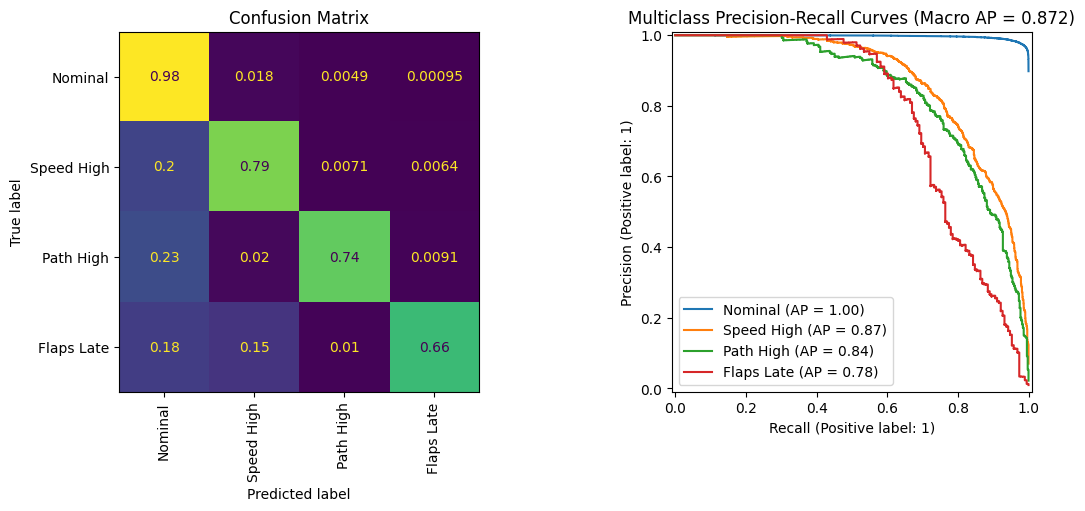

In [ ]:
# Confusion Matrix and Precision-Recall Curves

fig, axes = plt.subplots(1, 2, figsize=(12, 5),
    gridspec_kw={'width_ratios': [1, 1.6]},
    layout="constrained")

classes = [0, 1, 2, 3]

# 1. Confusion Matrix
cm_lgb = confusion_matrix(y_test, y_pred_lgb, labels=classes, normalize="true")

disp_cm_lgb = ConfusionMatrixDisplay(confusion_matrix=cm_lgb, display_labels=[class_names[c] for c in classes])

disp_cm_lgb.plot(ax=axes[0], colorbar=False, xticks_rotation=90)

axes[0].set_title("Confusion Matrix")

# 2. Multiclass Precision-Recall Curves
y_test_bin = label_binarize(y_test, classes=classes)

prob_indices = [list(lgb_optimal.classes_).index(c) for c in classes]

y_prob_ordered_lgb = y_prob_lgb[:, prob_indices]

for i, cls in enumerate(classes):
    PrecisionRecallDisplay.from_predictions(
        y_test_bin[:, i],
        y_prob_ordered_lgb[:, i],
        ax=axes[1],
        name=class_names[cls])

# 3. Macro Average Precision
ap_lgb = average_precision_score(y_test_bin, y_prob_ordered_lgb, average="macro")

axes[1].set_title(f"Multiclass Precision-Recall Curves (Macro AP = {ap_lgb:.3f})")

plt.show()


###**(3-B) LightGBM model with SMOTE-resampled data**


#### **Hyperparameter Optimization**

In [ ]:
# Create SMOTE + LightGBM pipeline
pipeline_lgb_smote = ImbPipeline([
    ('smote', SMOTE(random_state=10)),
    ('lgb', lgb.LGBMClassifier(
        objective="multiclass",
        num_class=4,
        boosting_type="gbdt",
        random_state=10,
        n_jobs=1, verbosity=-1))])

# Define hyperparameter distributions
param_grid_lgb_smote = {
    'lgb__n_estimators': [200, 500, 1000],
    'lgb__learning_rate': [0.03, 0.05, 0.1, 0.2],
    'lgb__max_depth': [4, 6, 8, 10, 12],
    'lgb__num_leaves': [10, 20, 30, 40],
    'lgb__min_child_samples': [20, 50, 100]
}

# Stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=10)

# RandomizedSearchCV
search_lgb_smote = RandomizedSearchCV(
    estimator=pipeline_lgb_smote,
    param_distributions=param_grid_lgb_smote,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    random_state=10,
    n_jobs=-1,
    refit=True,
    error_score="raise")

# Fit on ORIGINAL training data
search_lgb_smote.fit(X_train_selected, y_train)

# Best results
print("Best Parameters:")
print(search_lgb_smote.best_params_)

print("\nBest Cross-Validation Macro F1:", round(search_lgb_smote.best_score_, 3))


Best Parameters:
{'lgb__num_leaves': 40, 'lgb__n_estimators': 1000, 'lgb__min_child_samples': 100, 'lgb__max_depth': 10, 'lgb__learning_rate': 0.2}

Best Cross-Validation Macro F1: 0.772


#### **Model Training and Performance Evaluation**

In [ ]:
# Fit the optimal LightGBM + SMOTE using the optimal hyperparameters
lgb_smote_optimal = lgb.LGBMClassifier(objective="multiclass", num_class=4, boosting_type="gbdt", num_leaves=40,
min_child_samples=100, max_depth=10, learning_rate=0.2, n_estimators=1000,  random_state=10)

lgb_smote_optimal.fit(X_train_smote, y_train_smote)

# Predicted probabilities and labels on ORIGINAL test data
y_prob_lgb_smote = lgb_smote_optimal.predict_proba(X_test_selected)
y_pred_lgb_smote = lgb_smote_optimal.predict(X_test_selected)

# Classification report
classes = [0, 1, 2, 3]

print("LightGBM with SMOTE - Multiclass Classification")
print(classification_report(
    y_test,
    y_pred_lgb_smote,
    labels=classes,
    target_names=[class_names[c] for c in classes],
    zero_division=0), '\n')

# Macro Precision, Recall, and F1
precision_lgb_smote = precision_score(y_test, y_pred_lgb_smote, labels=classes, average="macro", zero_division=0)

recall_lgb_smote = recall_score(y_test, y_pred_lgb_smote, labels=classes, average="macro", zero_division=0)

f1_lgb_smote = f1_score(y_test, y_pred_lgb_smote, labels=classes, average="macro", zero_division=0)

# Convert actual labels to binary indicators
y_test_bin = label_binarize(y_test, classes=classes)

# Ensure probabilities follow the correct class order
prob_indices = [list(lgb_smote_optimal.classes_).index(c) for c in classes]

y_prob_ordered_lgb_smote = y_prob_lgb_smote[:, prob_indices]

# Calculate overall Macro Average Precision
ap_lgb_smote = average_precision_score(y_test_bin, y_prob_ordered_lgb_smote, average="macro")

# Calculate Average Precision for each class
ap_per_class_lgb_smote = average_precision_score(y_test_bin, y_prob_ordered_lgb_smote, average=None)

# Calculate Anomaly-only Macro AP (classes 1, 2, 3)
anomaly_ap_lgb_smote = np.mean(ap_per_class_lgb_smote[1:])

# Display results
print("Macro Precision:", round(precision_lgb_smote, 3))
print("Macro Recall:", round(recall_lgb_smote, 3))
print("Macro F1:", round(f1_lgb_smote, 3))
print("Macro Average Precision (AP):", round(ap_lgb_smote, 3))
print("Anomaly-only Macro AP:", round(anomaly_ap_lgb_smote, 3))

# Display individual class AP values
print("\nAverage Precision by Class:")
for cls, ap in zip(classes, ap_per_class_lgb_smote):
    print(f"{class_names[cls]}: {ap:.3f}")


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM with SMOTE - Multiclass Classification
              precision    recall  f1-score   support

     Nominal       0.98      0.92      0.95     17933
  Speed High       0.50      0.86      0.63      1403
   Path High       0.71      0.80      0.76       441
  Flaps Late       0.65      0.71      0.68       191

    accuracy                           0.92     19968
   macro avg       0.71      0.82      0.75     19968
weighted avg       0.94      0.92      0.92     19968
 

Macro Precision: 0.712
Macro Recall: 0.824
Macro F1: 0.755
Macro Average Precision (AP): 0.852
Anomaly-only Macro AP: 0.804

Average Precision by Class:
Nominal: 0.995
Speed High: 0.828
Path High: 0.835
Flaps Late: 0.749


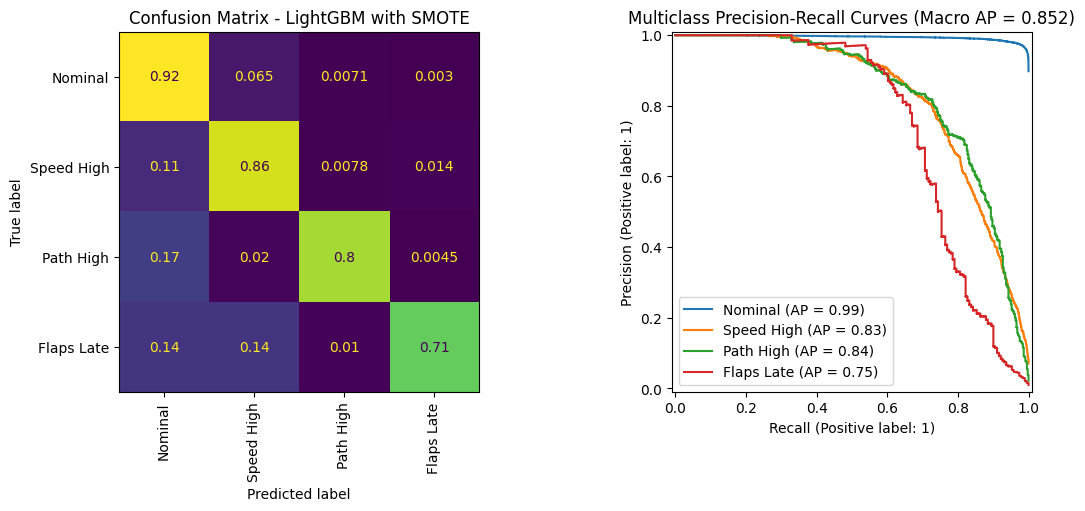

In [ ]:
# Confusion Matrix and Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1, 1.6]}, layout="constrained")

classes = [0, 1, 2, 3]

# 1. Confusion Matrix
cm_lgb_smote = confusion_matrix(y_test, y_pred_lgb_smote, labels=classes, normalize="true")

disp_cm_lgb_smote = ConfusionMatrixDisplay(confusion_matrix=cm_lgb_smote, display_labels=[class_names[c] for c in classes])

disp_cm_lgb_smote.plot(ax=axes[0], colorbar=False, xticks_rotation=90)

axes[0].set_title("Confusion Matrix - LightGBM with SMOTE")

# 2. Multiclass Precision-Recall Curves
y_test_bin = label_binarize(y_test, classes=classes)

prob_indices = [list(lgb_smote_optimal.classes_).index(c) for c in classes]

y_prob_ordered_lgb_smote = y_prob_lgb_smote[:, prob_indices]

for i, cls in enumerate(classes):
    PrecisionRecallDisplay.from_predictions(
        y_test_bin[:, i],
        y_prob_ordered_lgb_smote[:, i],
        ax=axes[1],
        name=class_names[cls])

# 3. Macro Average Precision
ap_lgb_smote = average_precision_score(y_test_bin, y_prob_ordered_lgb_smote, average="macro")

axes[1].set_title(f"Multiclass Precision-Recall Curves (Macro AP = {ap_lgb_smote:.3f})")

plt.show()



### **Comparison of LightGBM Models With and Without SMOTE Resampling**

The performance of **LightGBM with and without SMOTE resampling** was compared using the same held-out test dataset of **19,968 flights** across four classes: Nominal, Speed High, Path High, and Flaps Late.

#### **Overall Model Performance**

| Evaluation Metric | LightGBM without SMOTE | LightGBM with SMOTE |
|---|---:|---:|
| Accuracy | **0.96** | 0.92 |
| Macro Precision | **0.828** | 0.712 |
| Macro Recall | 0.792 | **0.824** |
| Macro F1-score | **0.808** | 0.755 |
| Macro Average Precision (AP) | **0.872** | 0.852 |
| Anomaly-only Macro AP | **0.830** | 0.804 |

#### **Anomaly-Class Performance**

| Flight Class | Metric | LightGBM without SMOTE | LightGBM with SMOTE |
|---|---|---:|---:|
| Speed High | Precision | **0.76** | 0.50 |
| | Recall | 0.79 | **0.86** |
| | F1-score | **0.77** | 0.63 |
| Path High | Precision | **0.77** | 0.71 |
| | Recall | 0.74 | **0.80** |
| | F1-score | 0.75 | **0.76** |
| Flaps Late | Precision | **0.81** | 0.65 |
| | Recall | 0.66 | **0.71** |
| | F1-score | **0.73** | 0.68 |

#### **Discussion and Conclusion**

**SMOTE improved recall across all three anomaly classes**, increasing Macro Recall from **0.792 to 0.824**. Recall increased from **0.79 to 0.86** for Speed High, **0.74 to 0.80** for Path High, and **0.66 to 0.71** for Flaps Late. However, these improvements were accompanied by reductions in precision, particularly for Speed High and Flaps Late, resulting in lower F1-scores for both classes. Path High showed a slight F1-score improvement (**0.75 to 0.76**).

Overall, **Macro F1-score decreased from 0.808 to 0.755**, while Macro Precision declined from **0.828 to 0.712**. Macro AP also decreased from **0.872 to 0.852**, and accuracy declined from **0.96 to 0.92**. Additionally, Nominal-class recall decreased from **0.98 to 0.92**, indicating more nominal flights were incorrectly classified as anomalies.

Consequently, **LightGBM without SMOTE was selected as the preferred LightGBM model**, as it achieved superior overall classification performance under the primary **Macro F1-score** criterion. Although SMOTE improved minority-class recall, the associated reductions in precision and overall performance outweighed these benefits.


##**(4) NN Model**

### **Hyperparameter Optimization**


In [ ]:
# Split training data into training and validation sets
X_train2, X_val, y_train2, y_val = train_test_split(X_train_selected, y_train, test_size=0.20, stratify=y_train, random_state=10)

classes = [0, 1, 2, 3]
num_classes = 4

# Convert validation labels to binary indicators for AP
y_val_bin = label_binarize(y_val, classes=classes)

# Hyperparameter tuning
results = []

for reg_value in [0.0, 0.001, 0.01, 0.1]:
    for dropout_rate in [0.0, 0.1, 0.3, 0.5]:

        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(10)

        model = keras.Sequential([
            layers.Input(shape=(X_train2.shape[1],)),

            # Hidden Layer 1
            layers.Dense(
                200, use_bias=False,
                kernel_regularizer=keras.regularizers.l2(reg_value)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rate),

            # Hidden Layer 2
            layers.Dense(
                100, use_bias=False,
                kernel_regularizer=keras.regularizers.l2(reg_value)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rate),

            # Hidden Layer 3
            layers.Dense(
                50, use_bias=False,
                kernel_regularizer=keras.regularizers.l2(reg_value)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rate),

            # Hidden Layer 4
            layers.Dense(
                25, use_bias=False,
                kernel_regularizer=keras.regularizers.l2(reg_value)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rate),

            # Multiclass output layer
            layers.Dense(num_classes, activation="softmax")])

        # Compile model
        model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

        # Early stopping
        early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

        # Train model
        history = model.fit(X_train2, y_train2, validation_data=(X_val, y_val), epochs=200, batch_size=64, callbacks=[early_stopping], verbose=0)

        # Predict validation probabilities and labels
        y_val_prob = model.predict(X_val, verbose=0)

        y_val_pred = np.argmax(y_val_prob, axis=1)

        # Calculate validation metrics
        val_loss = model.evaluate(X_val, y_val, verbose=0)[0]

        # Macro Average Precision
        val_ap = average_precision_score(y_val_bin, y_val_prob, average="macro")

        # Macro F1-score
        val_f1 = f1_score(y_val, y_val_pred, labels=classes, average="macro", zero_division=0)

        # Store results
        results.append({
            "Regularizer Value": reg_value,
            "Dropout Rate": dropout_rate,
            "val_loss": val_loss,
            "val_ap": val_ap,
            "val_f1": val_f1})

# Display tuning results
results_df = pd.DataFrame(results)
print(results_df)

# Select best combination based on Macro F1
best_result = results_df.loc[results_df["val_f1"].idxmax()]

# Extract optimal hyperparameters
optimal_reg_value = best_result["Regularizer Value"]
optimal_dropout_rate = best_result["Dropout Rate"]

print("\nOptimal Hyperparameters:")
print("L2 Regularization:", optimal_reg_value)
print("Dropout Rate:", optimal_dropout_rate)
print("Validation Macro F1:", round(best_result["val_f1"], 3))
print("Validation Macro AP:", round(best_result["val_ap"], 3))


    Regularizer Value  Dropout Rate  val_loss    val_ap    val_f1
0               0.000           0.0  0.156501  0.817162  0.755832
1               0.000           0.1  0.138550  0.846981  0.779685
2               0.000           0.3  0.132183  0.855204  0.791266
3               0.000           0.5  0.141273  0.840480  0.746546
4               0.001           0.0  0.174999  0.832492  0.762041
5               0.001           0.1  0.177799  0.838876  0.753807
6               0.001           0.3  0.185645  0.830262  0.736433
7               0.001           0.5  0.211487  0.803242  0.668446
8               0.010           0.0  0.172450  0.828283  0.747720
9               0.010           0.1  0.196420  0.789717  0.720435
10              0.010           0.3  0.222782  0.779018  0.693242
11              0.010           0.5  0.269696  0.629296  0.433230
12              0.100           0.0  0.192458  0.790025  0.717999
13              0.100           0.1  0.240271  0.710463  0.640913
14        

### **Model Training and Performance Evaluation**

In [ ]:
# Fit the NN model using the optimal hyperparameter values
optimal_reg_value = 0.0
optimal_dropout_rate = 0.3

# Set random seed for reproducibility
keras.backend.clear_session()
tf.keras.utils.set_random_seed(10)

model_NN_optimal = keras.Sequential([
    layers.Input(shape=(X_train_selected.shape[1],)),

    # Hidden Layer 1
    layers.Dense(200, use_bias=False,
        kernel_regularizer=keras.regularizers.l2(optimal_reg_value)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(optimal_dropout_rate),

    # Hidden Layer 2
    layers.Dense(100, use_bias=False,
        kernel_regularizer=keras.regularizers.l2(optimal_reg_value)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(optimal_dropout_rate),

    # Hidden Layer 3
    layers.Dense(50, use_bias=False,
        kernel_regularizer=keras.regularizers.l2(optimal_reg_value)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(optimal_dropout_rate),

    # Hidden Layer 4
    layers.Dense(25, use_bias=False,
        kernel_regularizer=keras.regularizers.l2(optimal_reg_value)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(optimal_dropout_rate),

    # Multiclass classification output (4 classes)
    layers.Dense(4, activation='softmax')])

# Compile
model_NN_optimal.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train on the original training data
history_nn_optimal = model_NN_optimal.fit(
    X_train_selected,
    np.asarray(y_train, dtype=int),
    epochs=200,
    batch_size=64,
    verbose=0)

# Predict probabilities and labels on original test data
y_prob_nn = model_NN_optimal.predict(X_test_selected, verbose=0)

y_pred_nn = np.argmax(y_prob_nn, axis=1)


Neural Network - Multiclass Classification
              precision    recall  f1-score   support

     Nominal       0.97      0.99      0.98     17933
  Speed High       0.88      0.65      0.75      1403
   Path High       0.86      0.71      0.77       441
  Flaps Late       0.80      0.68      0.73       191

    accuracy                           0.96     19968
   macro avg       0.88      0.76      0.81     19968
weighted avg       0.96      0.96      0.95     19968
 

Macro Precision: 0.875
Macro Recall: 0.755
Macro F1: 0.808
Macro Average Precision (AP): 0.874
Anomaly-only Macro AP: 0.833

Average Precision by Class:
Nominal: 0.997
Speed High: 0.853
Path High: 0.857
Flaps Late: 0.787


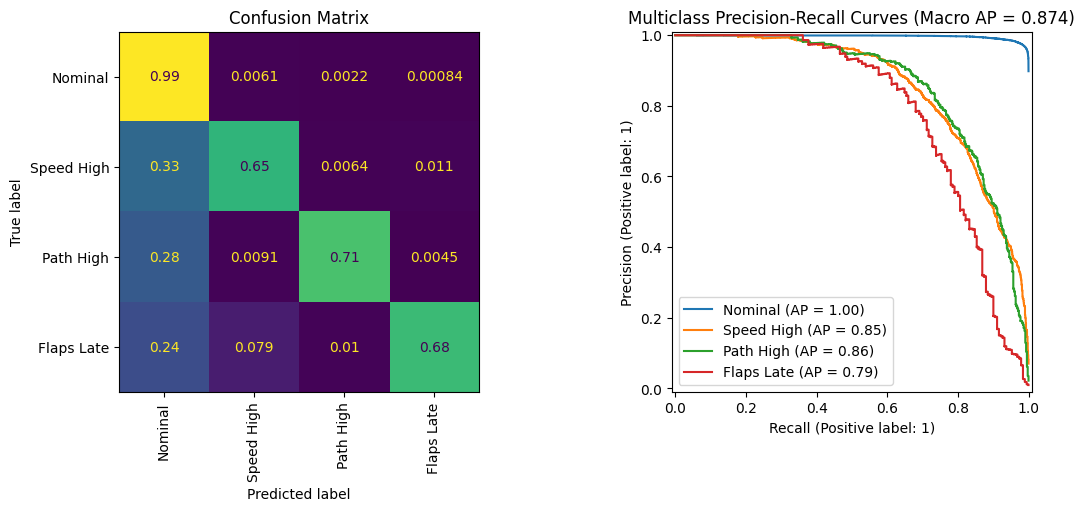

In [ ]:
# Evaluate Neural Network - Multiclass Classification
classes = [0, 1, 2, 3]

# 1. Predict probabilities and class labels
y_prob_nn = model_NN_optimal.predict(X_test_selected, verbose=0)
y_pred_nn = np.argmax(y_prob_nn, axis=1)

# 2. Classification Report
print("Neural Network - Multiclass Classification")
print(classification_report(y_test, y_pred_nn, labels=classes,
        target_names=[class_names[c] for c in classes],
        zero_division=0), '\n')

# 3. Macro Precision, Recall, and F1
precision_nn = precision_score(y_test, y_pred_nn, labels=classes, average="macro", zero_division=0)

recall_nn = recall_score(y_test, y_pred_nn, labels=classes, average="macro", zero_division=0)

f1_nn = f1_score(y_test, y_pred_nn, labels=classes, average="macro", zero_division=0)

# 4. Convert actual labels to binary indicators
y_test_bin = label_binarize(y_test, classes=classes)

# 5. Calculate Macro Average Precision
ap_nn = average_precision_score(y_test_bin, y_prob_nn, average="macro")

# 6. Calculate AP for each class
ap_per_class_nn = average_precision_score(y_test_bin, y_prob_nn, average=None)

# 7. Anomaly-only Macro AP (classes 1, 2, 3)
anomaly_ap_nn = ap_per_class_nn[1:].mean()

# 8. Display metrics
print("Macro Precision:", round(precision_nn, 3))
print("Macro Recall:", round(recall_nn, 3))
print("Macro F1:", round(f1_nn, 3))
print("Macro Average Precision (AP):", round(ap_nn, 3))
print("Anomaly-only Macro AP:", round(anomaly_ap_nn, 3))

print("\nAverage Precision by Class:")
for cls, ap in zip(classes, ap_per_class_nn):
    print(f"{class_names[cls]}: {ap:.3f}")


# 9. Confusion Matrix and Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1, 1.6]}, layout="constrained")

# Confusion Matrix (normalized by true class)
cm_nn = confusion_matrix(y_test, y_pred_nn, labels=classes, normalize="true")

disp_cm_nn = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=[class_names[c] for c in classes])

disp_cm_nn.plot(ax=axes[0], colorbar=False, xticks_rotation=90)

axes[0].set_title("Confusion Matrix")

# 10. Multiclass Precision-Recall Curves
for i, cls in enumerate(classes):
    PrecisionRecallDisplay.from_predictions(
        y_test_bin[:, i], y_prob_nn[:, i],
        ax=axes[1], name=class_names[cls])

axes[1].set_title(f"Multiclass Precision-Recall Curves (Macro AP = {ap_nn:.3f})")

plt.show()


# **STEP 4: MODEL COMPARISON & SELECTION**


In [ ]:
results = {"Balanced Random Forest": {"Precision": precision_brf, "Recall": recall_brf, "F1-score": f1_brf},
    "XGBoost": {"Precision": precision_xgb, "Recall": recall_xgb, "F1-score": f1_xgb},
    "LightGBM": {"Precision": precision_lgb, "Recall": recall_lgb, "F1-score": f1_lgb},
    "Neural Network": {"Precision": precision_nn, "Recall": recall_nn, "F1-score": f1_nn}}

df_results = pd.DataFrame(results).T
print(df_results.round(3))


                        Precision  Recall  F1-score
Balanced Random Forest      0.487   0.850     0.570
XGBoost                     0.880   0.757     0.811
LightGBM                    0.828   0.792     0.808
Neural Network              0.875   0.755     0.808


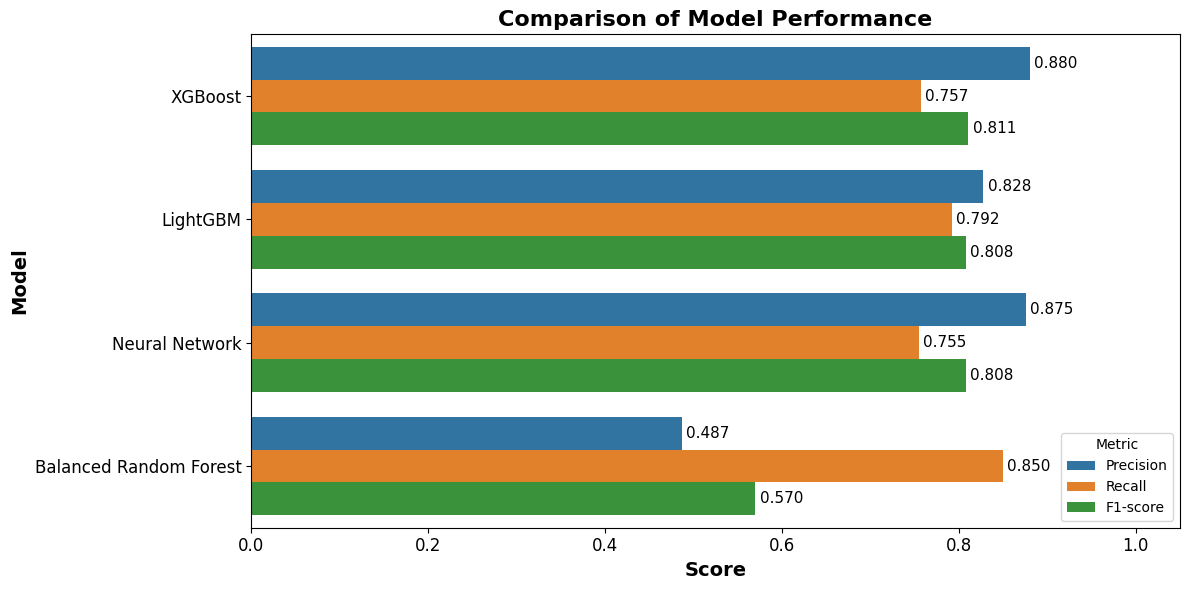

In [ ]:
# Sort models by F1-score (highest to lowest)
order_f1 = df_results.sort_values(by="F1-score", ascending=False).index

# Melt the DataFrame
df_melted = (df_results.reset_index().melt(id_vars="index", var_name="Metric", value_name="Score").rename(columns={"index": "Model"}))

# Create horizontal bar plot
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df_melted, y="Model", x="Score", hue="Metric", order=order_f1)

# Add values to the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=11)

# Bold title and axis labels
plt.title("Comparison of Model Performance", fontweight="bold")
plt.xlabel("Score", fontweight="bold")
plt.ylabel("Model", fontweight="bold")

# Bold title and axis labels
plt.title("Comparison of Model Performance", fontweight="bold", fontsize=16)
plt.xlabel("Score", fontweight="bold", fontsize=14)
plt.ylabel("Model", fontweight="bold", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()



### **Comparison of Multiclass Classification Model Performance**

The four candidate models were evaluated using **Macro Precision, Macro Recall, and Macro F1-score**, with **Macro F1-score selected as the primary model-selection criterion** because it balances Precision and Recall while assigning equal importance to all four flight classes: Nominal, Speed High, Path High, and Flaps Late.

Among the evaluated models, **XGBoost achieved the highest Macro F1-score (0.811)**, with a **Macro Precision of 0.880** and **Macro Recall of 0.757**, demonstrating the strongest overall balance between Precision and Recall. **Light Gradient Boosting Machine (LightGBM)** and the **Neural Network (NN)** exhibited nearly identical performance, both achieving a **Macro F1-score of 0.808**. LightGBM achieved a **Macro Precision of 0.828** and **Macro Recall of 0.792**, whereas NN achieved a **Macro Precision of 0.875** and **Macro Recall of 0.755**. These results indicate that LightGBM provided a more balanced relationship between Precision and Recall, while NN achieved higher Precision at the expense of lower Recall. The differences in Macro F1-score among XGBoost, LightGBM, and NN were relatively small, indicating comparable overall classification performance.

**Balanced Random Forest (BRF)** achieved the highest Macro Recall (**0.850**) among the four models, indicating greater sensitivity across the four flight classes. However, its substantially lower Macro Precision (**0.487**) resulted in the lowest Macro F1-score (**0.570**). This suggests that BRF correctly identified a larger proportion of actual observations across the classes but produced a higher proportion of false-positive predictions, substantially reducing its overall Precision and F1-score.

Overall, **XGBoost was selected as the preferred multiclass classification model** based on its highest Macro F1-score (**0.811**), followed closely by **LightGBM and NN (both 0.808)**. Although XGBoost demonstrated a slight advantage in Macro F1-score, LightGBM achieved higher Macro Recall (**0.792 versus 0.757**), while NN exhibited comparatively higher Macro Precision (**0.875**). **BRF remains a potential alternative when maximizing recall across the four classes is prioritized over minimizing false-positive predictions**, although its substantially lower Precision and Macro F1-score indicate an important trade-off in overall classification performance.


# **STEP 5: FEATURE IMPORTANCE AND INTERPRETATION**


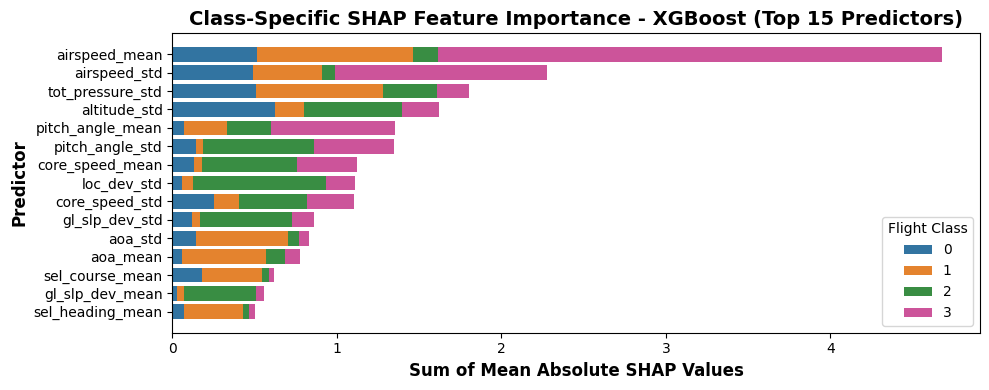

In [13]:
# Stacked SHAP Feature Importance - Multiclass XGBoost
# Create SHAP explainer for the trained XGBoost model
X_test_selected_df = pd.DataFrame(X_test_selected, columns=selected_features, index=X_test.index)
explainer = shap.TreeExplainer(xgb_optimal)
shap_values = explainer(X_test_selected_df)

# 1. Calculate mean absolute SHAP values for each feature and class
shap_importance = np.abs(shap_values.values).mean(axis=0)

# 2. Create DataFrame
shap_importance_df = pd.DataFrame(shap_importance, index=X_test_selected_df.columns, columns=class_names)

# 3. Calculate total SHAP importance across all four classes
shap_importance_df["Total"] = shap_importance_df.sum(axis=1)

# 4. Select top 15 predictors
top15_shap = (shap_importance_df.sort_values("Total", ascending=False).head(15))

# 5. Create stacked horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 4))

colors = ["#3274A1", "#E4832E", "#398D43", "#CC549A"]

left = np.zeros(len(top15_shap))

for i, cls in enumerate(class_names):
    ax.barh(
        top15_shap.index,
        top15_shap[cls],
        left=left,
        color=colors[i],
        label=cls)

    left += top15_shap[cls].to_numpy()

# 6. Customize figure
ax.invert_yaxis()

ax.set_xlabel("Sum of Mean Absolute SHAP Values", fontsize=12, fontweight="bold")
ax.set_ylabel("Predictor", fontsize=12, fontweight="bold")

ax.set_title("Class-Specific SHAP Feature Importance - XGBoost (Top 15 Predictors)", fontsize=14, fontweight="bold")

ax.legend(title="Flight Class", loc="lower right", frameon=True)

ax.tick_params(axis="both", labelsize=10)

plt.tight_layout()
plt.show()



### **SHAP Global Feature Importance – Multiclass Classification**

The **stacked SHAP feature-importance bar plot** illustrates the relative contributions of the **15 highest-ranked predictors** to the multiclass XGBoost model across four flight classes: **Nominal, Speed High, Path High, and Flaps Late**. Each colored segment represents the **mean absolute SHAP value** for a particular class, while the total bar length represents the **sum of mean absolute SHAP values across all four classes**.

Among the predictors, `airspeed_mean` emerged as the most influential feature, followed by `airspeed_std`, `tot_pressure_std`, and `altitude_std`. The contributions of `airspeed_mean` were particularly pronounced for **Flaps Late and Speed High**, whereas `airspeed_std` was more influential for **Flaps Late and Nominal**. Total pressure variability (`tot_pressure_std`) contributed primarily to **Speed High and Nominal**, while altitude variability (`altitude_std`) was particularly important for **Nominal and Path High** predictions.

Other influential predictors included `pitch_angle_mean`, `pitch_angle_std`, `core_speed_mean`, and `loc_dev_std`. Mean pitch angle was particularly important for **Flaps Late**, whereas pitch-angle variability, core-speed characteristics, and flight-path deviation measures contributed more strongly to **Path High** predictions. Angle-of-attack characteristics were more influential for **Speed High**.

Overall, **airspeed-related predictors dominated the model's global feature importance**, particularly for **Speed High and Flaps Late anomalies**, whereas **flight-path deviation and pitch-angle characteristics** were more prominent for **Path High**. Since the plot represents **absolute SHAP contributions**, it describes the magnitude rather than the direction of each predictor's effect on class-specific model outputs. Therefore, **class-specific SHAP beeswarm plots** provide complementary insights into the positive and negative contributions of individual predictors.


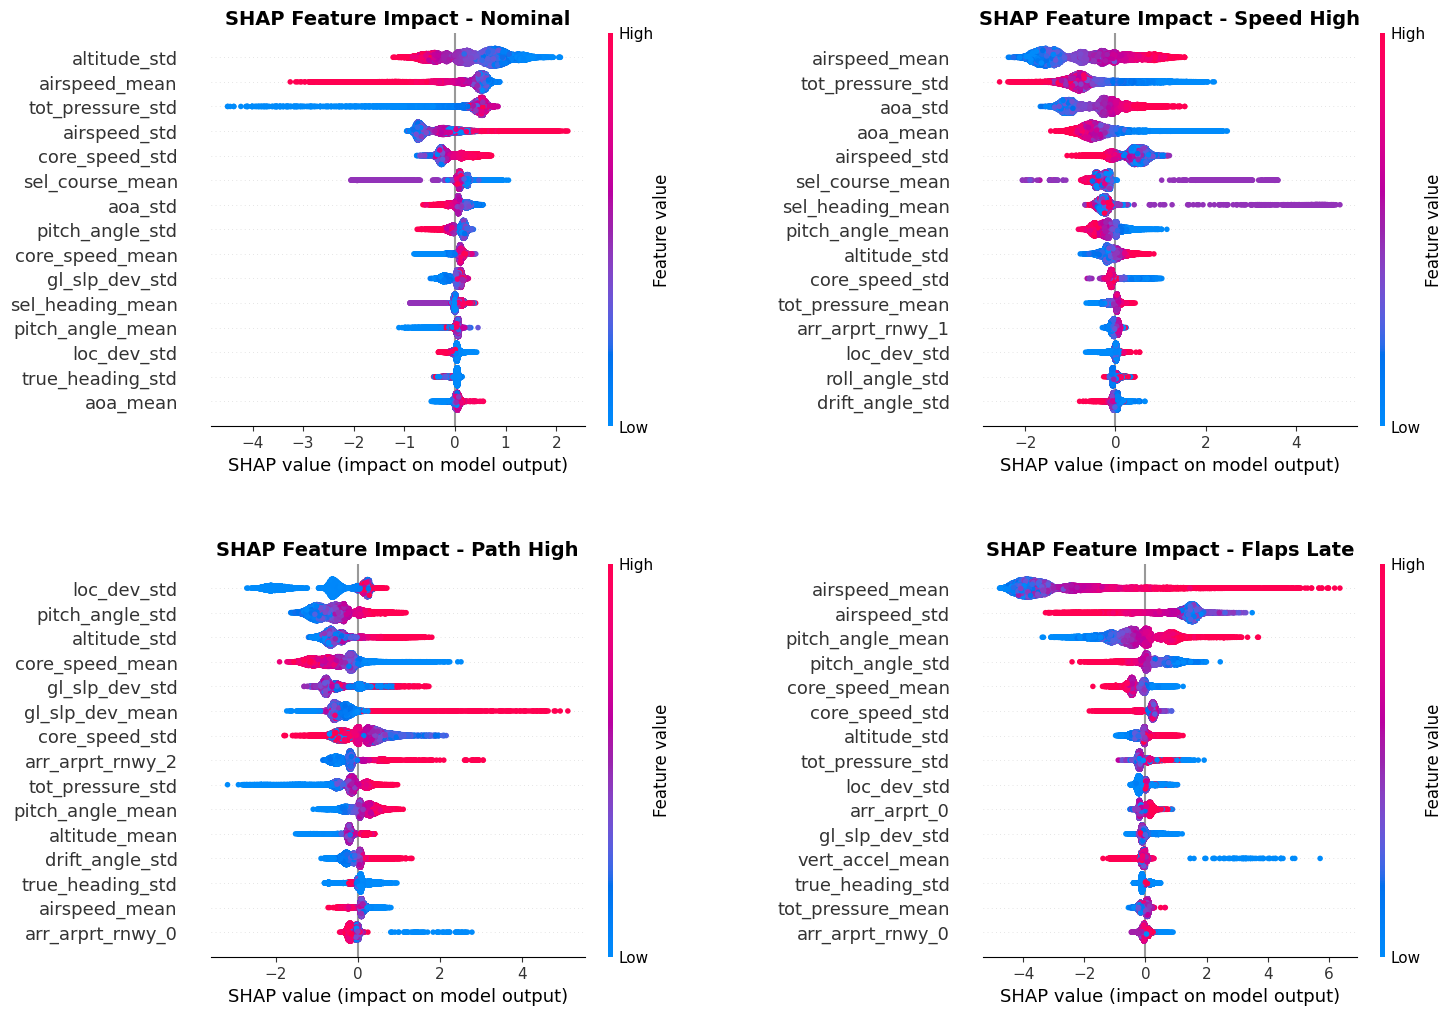

In [14]:
# Create a 2x2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, class_name in class_names.items():
    shap.plots.beeswarm(
        shap_values[:, :, i],
        max_display=15,
        group_remaining_features=False,
        ax=axes[i],
        plot_size=None,
        show=False)

    axes[i].set_title(f"SHAP Feature Impact - {class_name}", fontsize=14, fontweight="bold")

plt.subplots_adjust(wspace=0.65, hspace=0.35)

plt.show()



### **SHAP Feature Interpretation**

The above class-specific **SHAP beeswarm plots** show distinct patterns in how flight characteristics influenced XGBoost predictions across four categories: **Nominal (Class 0)**, **Speed High (Class 1)**, **Path High (Class 2)**, and **Flaps Late (Class 3)**. The results indicated that **airspeed characteristics**, **altitude variability**, **total pressure variability**, **pitch-angle characteristics**, and **flight-path deviation variability** played important roles in distinguishing nominal flights from different anomaly types. However, their relative importance and directional contributions varied across classes, suggesting that the model learned different combinations of flight characteristics for each anomaly category.

For the **Nominal class (Class 0)**, altitude variability (`altitude_std`), mean airspeed (`airspeed_mean`), and total pressure variability (`tot_pressure_std`) turned to be the most influential predictors. Higher mean airspeed and greater altitude variability generally produced negative SHAP contributions, reducing the model output for nominal flights. In contrast, higher total pressure variability tended to produce modest positive contributions, while lower values were associated with some strongly negative contributions. Higher airspeed variability (`airspeed_std`) also generally contributed positively to the Nominal class score. These findings indicate that the model distinguished nominal flights through combinations of airspeed, altitude, and pressure characteristics rather than a single predictor.

For the **Speed High class (Class 1)**, mean airspeed (`airspeed_mean`) was found to be the dominant predictor, with higher values producing strongly positive SHAP contributions. Total pressure variability (`tot_pressure_std`) and mean angle of attack (`aoa_mean`) generally exhibited negative directional relationships, whereas higher angle-of-attack variability (`aoa_std`) contributed positively to the class score. Higher airspeed variability (`airspeed_std`) generally produced negative contributions. Selected course (`sel_course_mean`) and selected heading (`sel_heading_mean`) exhibited mixed SHAP patterns, suggesting potentially nonlinear or interaction-dependent relationships.

For the **Path High class (Class 2)**, localizer deviation variability (`loc_dev_std`), pitch-angle variability (`pitch_angle_std`), altitude variability (`altitude_std`), and glideslope deviation measures (`gl_slp_dev_mean` and `gl_slp_dev_std`) were significant predictors. Higher values of these predictors generally resulted in positive SHAP contributions, whereas higher mean core speed (`core_speed_mean`) tended to decrease the class score. Total pressure variability (`tot_pressure_std`) also exhibited a generally positive directional relationship, while encoded airport-runway information contributed to variations in model predictions. These patterns suggest that the model identified path-related anomalies primarily through lateral and vertical flight-path deviations, pitch behavior, and altitude variability.

For the **Flaps Late class (Class 3)**, mean airspeed (`airspeed_mean`) emerged as the dominant predictor, with higher values producing strongly positive SHAP contributions. Higher airspeed variability (`airspeed_std`) and pitch-angle variability (`pitch_angle_std`) generally produced negative contributions, whereas higher mean pitch angle (`pitch_angle_mean`) tended to increase the class score. Higher mean core speed (`core_speed_mean`) also generally produced negative contributions. Additionally, lower mean vertical acceleration (`vert_accel_mean`) was associated with substantial positive SHAP contributions for some observations. These findings suggest that the model associated late-flap predictions with particular combinations of airspeed, pitch characteristics, and vertical flight dynamics.

Overall, the class-specific SHAP results demonstrate that **airspeed-related predictors were particularly influential for Speed High and Flaps Late anomalies**, whereas **flight-path deviation and pitch-angle variability** were more prominent for Path High anomalies. Nominal predictions were primarily distinguished by altitude variability, airspeed, and total pressure variability. Several predictors exhibited different or opposite directional effects across classes, emphasizing the importance of class-specific interpretation rather than relying solely on global feature-importance rankings.

### **Class-Specific SHAP Feature Effects**

| Feature | Nominal (Class 0) | Speed High (Class 1) | Path High (Class 2) | Flaps Late (Class 3) |
|---|---|---|---|---|
| `airspeed_mean` | ↓ **Strong** | ↑ **Strong** | ↓ Weak | ↑ **Strong** |
| `airspeed_std` | ↑ Moderate | ↓ Moderate | NS | ↓ **Strong** |
| `altitude_std` | ↓ **Strong** | ↑ Weak | ↑ **Strong** | Mixed / Weak |
| `altitude_mean` | NS | NS | ↓ Weak | NS |
| `tot_pressure_std` | ↑ **Strong** (asymmetric) | ↓ **Strong** | ↑ Moderate | Mixed / Weak |
| `tot_pressure_mean` | NS | ↑ Weak | NS | Mixed / Weak |
| `pitch_angle_mean` | Mixed / Weak | ↓ Moderate | ↑ Weak | ↑ **Strong** |
| `pitch_angle_std` | ↓ Weak | ↓ Weak | ↑ **Strong** | ↓ Moderate |
| `aoa_mean` | ↑ Weak | ↓ **Strong** | NS | NS |
| `aoa_std` | ↓ Weak | ↑ **Strong** | NS | NS |
| `core_speed_mean` | ↑ Weak | NS | ↓ **Strong** | ↓ Moderate |
| `core_speed_std` | ↑ Moderate | ↓ Weak | ↓ Moderate | ↓ Weak |
| `loc_dev_std` | ↓ Weak | Mixed / Weak | ↑ **Strong** | ↑ Weak |
| `gl_slp_dev_mean` | NS | NS | ↑ **Strong** | NS |
| `gl_slp_dev_std` | ↑ Weak | NS | ↑ Moderate | ↓ Weak |
| `sel_course_mean` | Mixed / Moderate | Mixed / Moderate | NS | NS |
| `sel_heading_mean` | Mixed / Weak | Mixed / Moderate | NS | NS |
| `true_heading_std` | Mixed / Weak | NS | ↓ Weak | ↓ Weak |
| `drift_angle_std` | NS | ↓ Weak | ↑ Weak | NS |
| `roll_angle_std` | NS | Mixed / Weak | NS | NS |
| `vert_accel_mean` | NS | NS | NS | ↓ Moderate |
| `arr_arprt_rnwy_0` | NS | NS | Mixed / Weak | Mixed / Weak |
| `arr_arprt_rnwy_1` | NS | Mixed / Weak | NS | NS |
| `arr_arprt_rnwy_2` | NS | NS | Mixed / Moderate | NS |
| `arr_arprt_0` | NS | NS | NS | Mixed / Weak |

**Notes:**

- **↑** Higher predictor values generally increase the probability of occurrence for the corresponding class.
- **↓** Higher predictor values generally decrease the probability of occurrence for the corresponding class.
- **Strong / Moderate / Weak** represent qualitative effect magnitudes inferred from the SHAP distributions.
- **Mixed** indicates that both positive and negative SHAP contributions occur without a consistent directional pattern.
- **NS (Not Shown)** indicates that the predictor was not displayed among the top 15 features in the corresponding class-specific beeswarm plot. This does not imply zero feature importance.
- The SHAP analysis was performed on the independent **test dataset** to examine the feature contributions underlying the trained model's predictions.


# **RECOMMENDATIONS FOR FUTURE WORK**

In the present study, approximately 160 time-stamped observations per flight were aggregated into flight-level features using the **mean and standard deviation**, potentially obscuring important temporal patterns and short-duration deviations. Future research could explore **unaggregated time-series data** using sequential deep-learning models, such as an **LSTM-based multiclass classifier** or an **LSTM autoencoder with a classification head**. Their performance could then be compared with the models developed here to determine whether capturing temporal dependencies improves the **detection and classification of flight anomalies**.

A second direction for future research is to incorporate additional **airport-specific operational characteristics** into the prediction models, such as airport traffic volume, number of runways, runway configuration, and weather conditions. These factors may influence the likelihood and characteristics of flight anomalies. In addition, incorporating **aircraft-specific characteristics**, such as aircraft model, aircraft age, and engine type, may further improve model performance, as different aircraft types may exhibit different approach dynamics, deceleration behavior, and flap-deployment procedures.


# **REFERENCES**

Campesato, O. (2023). Python 3 and Feature Engineering.

Galli, S. (2020). Python feature engineering cookbook. Packt Publishing.

Galli, S. (2021). Feature-engine: A Python package for feature engineering for machine learning. Journal of Open Source Software, 6(65), p.3642.

Lee, H., Li, G., Rai, A. and Chattopadhyay, A., 2020. Real-time anomaly detection framework using a support vector regression for the safety monitoring of commercial aircraft. Advanced Engineering Informatics, 44, p.101071.

Kim, M., Kho, S.Y. and Kim, D.K., 2017. Hierarchical ordered model for injury severity of pedestrian crashes in South Korea. Journal of safety research, 61, pp.33-40.

Masís, S., 2021. Interpretable machine learning with Python (pp. 183-209). Birmingham, UK: Packt Publishing.

Memarzadeh, M., Matthews, B. and Templin, T., 2022. Multiclass anomaly detection in flight data using semi-supervised explainable deep learning model. Journal of Aerospace Information Systems, 19(2), pp.83-97.

Raja, M.N.A., Abdoun, T. and El-Sekelly, W., 2026. Smart Ensemble Modeling for Multiclass Lateral‑Spreading Prediction. Applied Soft Computing, p.115163.

Shaheed, M.S., Gkritza, K., Carriquiry, A.L. and Hallmark, S.L., 2016. Analysis of occupant injury severity in winter weather crashes: A fully Bayesian multivariate approach. Analytic methods in accident research, 11, pp.33-47.

Zhang, T., Ning, Z., Fan, Y., Zidong, Z., Lei, J., Du, S. and He, S., 2026. Interpretable machine learning for multiclass trajectory prediction in cardiovascular-kidney-metabolic syndrome stage: development and external validation. Frontiers in Endocrinology, 17, p.1907821.